# CU-BEMS Floor 6 Zone 1/2/4/5 Data Preparation and EDA

本 notebook 针对 CU-BEMS 数据集进行重新优化：仅选取 **2018 年 Floor 6**，并使用 **Zone 1、Zone 2、Zone 4、Zone 5** 作为主要分析对象。

处理目标：

- 每个 selected Zone 的 AC 设备按时间点在 Zone 内求和，形成单一 `total_AC_power_kw`。
- 原始 individual AC 设备列不进入最终建模表。
- Zone 1、Zone 2、Zone 4、Zone 5 统一成纵向 long format。
- 分析范围限定为 **2018-07-01 至 2018-09-01 23:59:00**。
- 进行数据质量检查、rolling mean 平滑和 EDA，为后续 anomaly detection 建立数据基础。

In [23]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

plt.style.use("default")

## 1. Configuration

In [24]:
from pathlib import Path
import pandas as pd


# ============================================================
# 1. Analysis Scope
# ============================================================

FLOOR = 6

YEARS = [2018]

SELECTED_ZONES = [1, 2, 4, 5]

ANALYSIS_START = pd.Timestamp("2018-07-01 00:00:00")

ANALYSIS_END = pd.Timestamp("2018-09-01 23:59:00")


# ============================================================
# 2. Rolling Features
# ============================================================

ROLLING_WINDOW_RECORDS = 15

ROLLING_MIN_PERIODS = 5


# ============================================================
# 3. AC Operating-State Parameters
# ============================================================

# Exclude ±15 min around startup / shutdown when defining
# stable operating periods for rolling-noise comparison.
TRANSITION_BUFFER_MIN = ROLLING_WINDOW_RECORDS

# Minimum threshold below which zone AC power is treated as OFF.
MIN_OFF_THRESHOLD_KW = 0.5

# Zone-specific OFF threshold:
# max(MIN_OFF_THRESHOLD_KW, Zone Q95 power × this ratio)
OFF_RATIO_OF_Q95 = 0.02


# ============================================================
# 4. Variables
# ============================================================

VALUE_COLUMNS = [
    "total_AC_power_kw",
    "light_power_kw",
    "plug_power_kw",
    "temperature_c",
    "humidity_pct",
    "lux",
]

POWER_COLUMNS = [
    "total_AC_power_kw",
    "light_power_kw",
    "plug_power_kw",
]

COMPONENT_POWER_COLUMNS = POWER_COLUMNS.copy()

ENVIRONMENT_COLUMNS = [
    "temperature_c",
    "humidity_pct",
    "lux",
]

KEY_COLUMNS = [
    "timestamp",
    "floor",
    "zone",
]


# ============================================================
# 5. Project Paths
# ============================================================

NOTEBOOK_CWD = Path.cwd()

# Notebook is expected to be inside Data_pre/
# so the parent folder is the project root.
if NOTEBOOK_CWD.name == "Data_pre":
    PROJECT_DIR = NOTEBOOK_CWD.parent
else:
    # Useful when VS Code / Jupyter starts from project root
    PROJECT_DIR = NOTEBOOK_CWD


RAW_DATA_DIR = PROJECT_DIR / "Raw data"

RAW_DATA_FILE = RAW_DATA_DIR / "2018Floor6.csv"


if not RAW_DATA_FILE.exists():
    raise FileNotFoundError(
        f"Could not locate raw data file:\n{RAW_DATA_FILE}"
    )

RAW_DATA_INPUT = RAW_DATA_FILE


# ============================================================
# 6. Output Paths
# ============================================================

OUTPUT_DIR = (
    PROJECT_DIR
    / "outputs"
    / "floor6_zone1245_2018_jul01_sep01_total_ac_eda"
)

FIGURE_DIR = OUTPUT_DIR / "figures"

TABLE_DIR = OUTPUT_DIR / "eda_tables"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 7. Final Dataset
# ============================================================

FINAL_DATASET = (
    OUTPUT_DIR
    / "floor6_zone1245_cleaned_features_2018_jul01_sep01.csv.gz"
)

BASELINE_READY_DATASET = (
    OUTPUT_DIR
    / "floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz"
)


# ============================================================
# 8. Configuration Check
# ============================================================

print("Notebook working directory:", NOTEBOOK_CWD)
print("Project directory:", PROJECT_DIR)
print("Raw data input:", RAW_DATA_INPUT)
print("Output directory:", OUTPUT_DIR)
print("Figure directory:", FIGURE_DIR)
print("Table directory:", TABLE_DIR)
print("Final dataset:", FINAL_DATASET)
print("Baseline-ready dataset:", BASELINE_READY_DATASET)

Notebook working directory: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\Data_pre
Project directory: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis
Raw data input: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\Raw data\2018Floor6.csv
Output directory: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda
Figure directory: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures
Table directory: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone12

## 2. Floor 6 Zone Schema

In [25]:
AC_COLUMN_PATTERN = re.compile(r"^z(?P<zone>\d+)_AC(?P<meter>\d+)\(kW\)$")
AC_TOTAL_COLUMN_TEMPLATE = "z{zone}_AC_total(kW)"

ZONE_SPECS = {
    1: {
        "light_col": "z1_Light(kW)",
        "plug_col": "z1_Plug(kW)",
        "temperature_col": "z1_S1(degC)",
        "humidity_col": "z1_S1(RH%)",
        "lux_col": "z1_S1(lux)",
    },
    2: {
        "light_col": "z2_Light(kW)",
        "plug_col": "z2_Plug(kW)",
        "temperature_col": "z2_S1(degC)",
        "humidity_col": "z2_S1(RH%)",
        "lux_col": "z2_S1(lux)",
    },
    4: {
        "light_col": "z4_Light(kW)",
        "plug_col": "z4_Plug(kW)",
        "temperature_col": "z4_S1(degC)",
        "humidity_col": "z4_S1(RH%)",
        "lux_col": "z4_S1(lux)",
    },
    5: {
        "light_col": "z5_Light(kW)",
        "plug_col": "z5_Plug(kW)",
        "temperature_col": "z5_S1(degC)",
        "humidity_col": "z5_S1(RH%)",
        "lux_col": "z5_S1(lux)",
    },
}

required_columns = {"Date"}
for spec in ZONE_SPECS.values():
    required_columns.update([spec["light_col"], spec["plug_col"], spec["temperature_col"], spec["humidity_col"], spec["lux_col"]])

print("Selected zones:", SELECTED_ZONES)
print("AC column detection pattern:", AC_COLUMN_PATTERN.pattern)
print("Required non-AC raw columns:", len(required_columns))

Selected zones: [1, 2, 4, 5]
AC column detection pattern: ^z(?P<zone>\d+)_AC(?P<meter>\d+)\(kW\)$
Required non-AC raw columns: 21


## 3. Load Raw Data

In [26]:
def parse_timestamp_column(date_series: pd.Series) -> pd.Series:
    timestamps = pd.to_datetime(date_series, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    missing_mask = timestamps.isna()
    if missing_mask.any():
        timestamps.loc[missing_mask] = pd.to_datetime(date_series.loc[missing_mask], format="%d/%m/%Y %H:%M", errors="coerce")
    return timestamps


def load_floor_raw_data(raw_data_input: Path, floor: int, years: list[int], required_cols: set[str]) -> tuple[pd.DataFrame, pd.DataFrame]:
    parts = []
    audit_rows = []

    if raw_data_input.is_file():
        # Current workspace keeps one single CSV file instead of a Raw Data directory.
        stem = raw_data_input.stem
        year = int(stem[:4]) if stem[:4].isdigit() else years[0]
        file_path = raw_data_input
        raw = pd.read_csv(file_path)
        missing_required = sorted(required_cols.difference(raw.columns))
        if missing_required:
            raise ValueError(f"{file_path.name} is missing required columns: {missing_required}")

        raw.insert(0, "source_file", file_path.name)
        raw.insert(0, "floor", floor)
        raw.insert(0, "year", year)
        raw["timestamp"] = parse_timestamp_column(raw["Date"])

        audit_rows.append({
            "year": year,
            "file_name": file_path.name,
            "rows": len(raw),
            "columns": len(raw.columns),
            "invalid_timestamp_rows": int(raw["timestamp"].isna().sum()),
            "min_timestamp": raw["timestamp"].min(),
            "max_timestamp": raw["timestamp"].max(),
        })
        parts.append(raw)
        all_loaded = pd.concat(parts, ignore_index=True)
        return all_loaded, pd.DataFrame(audit_rows)

    for year in years:
        file_path = raw_data_input / f"{year}Floor{floor}.csv"
        raw = pd.read_csv(file_path)
        missing_required = sorted(required_cols.difference(raw.columns))
        if missing_required:
            raise ValueError(f"{file_path.name} is missing required columns: {missing_required}")

        raw.insert(0, "source_file", file_path.name)
        raw.insert(0, "floor", floor)
        raw.insert(0, "year", year)
        raw["timestamp"] = parse_timestamp_column(raw["Date"])

        audit_rows.append({
            "year": year,
            "file_name": file_path.name,
            "rows": len(raw),
            "columns": len(raw.columns),
            "invalid_timestamp_rows": int(raw["timestamp"].isna().sum()),
            "min_timestamp": raw["timestamp"].min(),
            "max_timestamp": raw["timestamp"].max(),
        })
        parts.append(raw)

    all_loaded = pd.concat(parts, ignore_index=True)
    return all_loaded, pd.DataFrame(audit_rows)

raw_wide, load_audit = load_floor_raw_data(RAW_DATA_INPUT, FLOOR, YEARS, required_columns)
load_audit.to_csv(OUTPUT_DIR / "01_load_audit_floor6.csv", index=False)

display(load_audit.head(20))
display(raw_wide.head(20))
print("Combined raw rows:", f"{len(raw_wide):,}")
print("Combined raw columns:", len(raw_wide.columns))


,year,file_name,rows,columns,invalid_timestamp_rows,min_timestamp,max_timestamp
0,2018,2018Floor6.csv,264960,34,0,2018-07-01,2018-12-31 23:59:00


,year,floor,source_file,Date,z1_AC1(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z4_AC1(kW),z4_AC2(kW),z4_AC3(kW),z4_AC4(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux),timestamp
0,2018,6,2018Floor6.csv,2018-07-01 00:00:00,0.0,0.0,0.31,27.57,72.19,0.0,0.0,0.01,0.13,27.79,70.56,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.07,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.48,0.0,2018-07-01 00:00:00
1,2018,6,2018Floor6.csv,2018-07-01 00:01:00,0.0,0.0,0.31,27.57,72.18,0.0,0.0,0.01,0.13,27.78,70.56,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.06,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.48,0.0,2018-07-01 00:01:00
2,2018,6,2018Floor6.csv,2018-07-01 00:02:00,0.0,0.0,0.31,27.57,72.18,0.0,0.0,0.01,0.13,27.77,70.56,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.11,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.50,0.0,2018-07-01 00:02:00
3,2018,6,2018Floor6.csv,2018-07-01 00:03:00,0.0,0.0,0.26,27.56,72.17,0.0,0.0,0.01,0.13,27.77,70.57,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.22,27.27,71.76,0.0,0.0,0.0,0.01,28.9,68.51,0.0,2018-07-01 00:03:00
4,2018,6,2018Floor6.csv,2018-07-01 00:04:00,0.0,0.0,0.26,27.56,72.17,0.0,0.0,0.01,0.13,27.77,70.57,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.21,27.27,71.76,0.0,0.0,0.0,0.01,28.9,68.52,0.0,2018-07-01 00:04:00
5,2018,6,2018Floor6.csv,2018-07-01 00:05:00,0.0,0.0,0.23,27.56,72.16,0.0,0.0,0.01,0.11,27.77,70.58,0.0,0.02,0.22,0.0,0.0,0.0,0.0,0.0,0.21,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.52,0.0,2018-07-01 00:05:00
6,2018,6,2018Floor6.csv,2018-07-01 00:06:00,0.0,0.0,0.23,27.56,72.15,0.0,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.21,27.28,71.75,0.0,0.0,0.0,0.01,NaN,NaN,NaN,2018-07-01 00:06:00
7,2018,6,2018Floor6.csv,2018-07-01 00:07:00,0.0,0.0,0.23,27.56,72.14,0.0,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.13,27.28,71.75,0.0,0.0,0.0,0.01,NaN,NaN,NaN,2018-07-01 00:07:00
8,2018,6,2018Floor6.csv,2018-07-01 00:08:00,0.0,0.0,0.19,27.56,72.13,0.0,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.07,27.27,71.75,0.0,0.0,0.0,0.02,28.8,68.53,0.0,2018-07-01 00:08:00
9,2018,6,2018Floor6.csv,2018-07-01 00:09:00,0.0,0.0,0.23,27.56,72.13,0.0,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.07,27.27,71.74,0.0,0.0,0.0,0.06,28.8,68.53,0.0,2018-07-01 00:09:00


Combined raw rows: 264,960
Combined raw columns: 34


## 4. Aggregate Zone-Level AC Before Long Merge

Before converting the data into long format, AC meter columns are identified separately for each selected zone using the raw column names. Each zone's AC columns are summed row-by-row into one zone-level total column such as `z2_AC_total(kW)`. The original individual AC meter columns are then dropped from the working wide table, so the final long-format dataset has only one standard `total_AC_power_kw` field per zone.

In [27]:
def identify_zone_ac_columns(raw: pd.DataFrame, selected_zones: list[int]) -> dict[int, list[str]]:
    zone_ac_columns = {zone: [] for zone in selected_zones}
    for column in raw.columns:
        match = AC_COLUMN_PATTERN.match(column)
        if not match:
            continue
        zone = int(match.group("zone"))
        if zone in zone_ac_columns:
            zone_ac_columns[zone].append(column)

    def meter_number(column: str) -> int:
        return int(AC_COLUMN_PATTERN.match(column).group("meter"))

    return {zone: sorted(columns, key=meter_number) for zone, columns in zone_ac_columns.items()}


def aggregate_zone_ac_before_long_merge(
    raw: pd.DataFrame,
    selected_zones: list[int],
) -> tuple[pd.DataFrame, pd.DataFrame, dict[int, dict]]:
    aggregated = raw.copy()
    before_columns = len(aggregated.columns)
    zone_ac_columns = identify_zone_ac_columns(aggregated, selected_zones)
    zone_ac_feature_map = {}
    audit_rows = []
    columns_to_drop = []

    for zone in selected_zones:
        raw_ac_columns = zone_ac_columns[zone]
        total_ac_column = AC_TOTAL_COLUMN_TEMPLATE.format(zone=zone) if raw_ac_columns else None

        if raw_ac_columns:
            aggregated[total_ac_column] = (
                aggregated[raw_ac_columns]
                .apply(pd.to_numeric, errors="coerce")
                .sum(axis=1, min_count=1)
            )
            columns_to_drop.extend(raw_ac_columns)

        zone_ac_feature_map[zone] = {
            "raw_ac_cols": raw_ac_columns,
            "ac_col": total_ac_column,
            "ac_meter_count": len(raw_ac_columns),
        }
        audit_rows.append({
            "step": "aggregate_zone_ac_before_long_merge",
            "source_zone": zone,
            "raw_ac_columns_summed": len(raw_ac_columns),
            "raw_ac_columns": ", ".join(raw_ac_columns),
            "new_ac_total_column": total_ac_column,
            "missing_aggregated_ac_values": int(aggregated[total_ac_column].isna().sum()) if total_ac_column else np.nan,
        })

    aggregated = aggregated.drop(columns=columns_to_drop)
    retained_original_ac_columns = [column for columns in zone_ac_columns.values() for column in columns if column in aggregated.columns]

    audit = pd.DataFrame(audit_rows)
    audit["columns_before"] = before_columns
    audit["columns_after"] = len(aggregated.columns)
    audit["rows"] = len(aggregated)
    audit["original_ac_columns_retained_after_aggregation"] = len(retained_original_ac_columns)

    return aggregated, audit, zone_ac_feature_map


raw_wide_aggregated, zone_ac_aggregation_audit, zone_ac_feature_map = aggregate_zone_ac_before_long_merge(
    raw_wide,
    SELECTED_ZONES,
)

for zone, ac_meta in zone_ac_feature_map.items():
    ZONE_SPECS[zone].update(ac_meta)

zone_ac_aggregation_audit.to_csv(OUTPUT_DIR / "02_zone_ac_aggregation_audit.csv", index=False)
raw_wide_aggregated.head(1000).to_csv(OUTPUT_DIR / "02_raw_wide_after_zone_ac_aggregation_preview.csv", index=False)

display(zone_ac_aggregation_audit.head(20))
display(raw_wide_aggregated.head(20))
print("Original selected-zone AC columns retained:", [col for cols in identify_zone_ac_columns(raw_wide, SELECTED_ZONES).values() for col in cols if col in raw_wide_aggregated.columns])

,step,source_zone,raw_ac_columns_summed,raw_ac_columns,new_ac_total_column,missing_aggregated_ac_values,columns_before,columns_after,rows,original_ac_columns_retained_after_aggregation
0,aggregate_zone_ac_before_long_merge,1,1,z1_AC1(kW),z1_AC_total(kW),473,34,31,264960,0
1,aggregate_zone_ac_before_long_merge,2,1,z2_AC1(kW),z2_AC_total(kW),474,34,31,264960,0
2,aggregate_zone_ac_before_long_merge,4,4,"z4_AC1(kW), z4_AC2(kW), z4_AC3(kW), z4_AC4(kW)",z4_AC_total(kW),395,34,31,264960,0
3,aggregate_zone_ac_before_long_merge,5,1,z5_AC1(kW),z5_AC_total(kW),473,34,31,264960,0


,year,floor,source_file,Date,z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux),timestamp,z1_AC_total(kW),z2_AC_total(kW),z4_AC_total(kW),z5_AC_total(kW)
0,2018,6,2018Floor6.csv,2018-07-01 00:00:00,0.0,0.31,27.57,72.19,0.0,0.01,0.13,27.79,70.56,0.0,0.02,0.27,0.0,0.07,27.28,71.76,0.0,0.0,0.01,28.9,68.48,0.0,2018-07-01 00:00:00,0.0,0.0,0.0,0.0
1,2018,6,2018Floor6.csv,2018-07-01 00:01:00,0.0,0.31,27.57,72.18,0.0,0.01,0.13,27.78,70.56,0.0,0.02,0.27,0.0,0.06,27.28,71.76,0.0,0.0,0.01,28.9,68.48,0.0,2018-07-01 00:01:00,0.0,0.0,0.0,0.0
2,2018,6,2018Floor6.csv,2018-07-01 00:02:00,0.0,0.31,27.57,72.18,0.0,0.01,0.13,27.77,70.56,0.0,0.02,0.27,0.0,0.11,27.28,71.76,0.0,0.0,0.01,28.9,68.50,0.0,2018-07-01 00:02:00,0.0,0.0,0.0,0.0
3,2018,6,2018Floor6.csv,2018-07-01 00:03:00,0.0,0.26,27.56,72.17,0.0,0.01,0.13,27.77,70.57,0.0,0.02,0.27,0.0,0.22,27.27,71.76,0.0,0.0,0.01,28.9,68.51,0.0,2018-07-01 00:03:00,0.0,0.0,0.0,0.0
4,2018,6,2018Floor6.csv,2018-07-01 00:04:00,0.0,0.26,27.56,72.17,0.0,0.01,0.13,27.77,70.57,0.0,0.02,0.27,0.0,0.21,27.27,71.76,0.0,0.0,0.01,28.9,68.52,0.0,2018-07-01 00:04:00,0.0,0.0,0.0,0.0
5,2018,6,2018Floor6.csv,2018-07-01 00:05:00,0.0,0.23,27.56,72.16,0.0,0.01,0.11,27.77,70.58,0.0,0.02,0.22,0.0,0.21,27.28,71.76,0.0,0.0,0.01,28.9,68.52,0.0,2018-07-01 00:05:00,0.0,0.0,0.0,0.0
6,2018,6,2018Floor6.csv,2018-07-01 00:06:00,0.0,0.23,27.56,72.15,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.21,27.28,71.75,0.0,0.0,0.01,NaN,NaN,NaN,2018-07-01 00:06:00,0.0,0.0,0.0,0.0
7,2018,6,2018Floor6.csv,2018-07-01 00:07:00,0.0,0.23,27.56,72.14,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.13,27.28,71.75,0.0,0.0,0.01,NaN,NaN,NaN,2018-07-01 00:07:00,0.0,0.0,0.0,0.0
8,2018,6,2018Floor6.csv,2018-07-01 00:08:00,0.0,0.19,27.56,72.13,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.07,27.27,71.75,0.0,0.0,0.02,28.8,68.53,0.0,2018-07-01 00:08:00,0.0,0.0,0.0,0.0
9,2018,6,2018Floor6.csv,2018-07-01 00:09:00,0.0,0.23,27.56,72.13,0.0,0.01,0.13,27.76,70.58,0.0,0.02,0.27,0.0,0.07,27.27,71.74,0.0,0.0,0.06,28.8,68.53,0.0,2018-07-01 00:09:00,0.0,0.0,0.0,0.0


Original selected-zone AC columns retained: []


## 5. Convert Selected Zones to Long Format

In [28]:
def to_numeric_frame(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    return df[columns].apply(pd.to_numeric, errors="coerce")


def build_zone_long(raw: pd.DataFrame, zone: int, spec: dict) -> pd.DataFrame:
    out = raw[["timestamp", "year", "floor", "source_file"]].copy()
    out["zone"] = zone

    ac_col = spec["ac_col"]
    if ac_col is not None:
        out["total_AC_power_kw"] = pd.to_numeric(raw[ac_col], errors="coerce")
    else:
        out["total_AC_power_kw"] = np.nan

    out["light_power_kw"] = pd.to_numeric(raw[spec["light_col"]], errors="coerce")
    out["plug_power_kw"] = pd.to_numeric(raw[spec["plug_col"]], errors="coerce")

    out["temperature_c"] = pd.to_numeric(raw[spec["temperature_col"]], errors="coerce")
    out["humidity_pct"] = pd.to_numeric(raw[spec["humidity_col"]], errors="coerce")
    out["lux"] = pd.to_numeric(raw[spec["lux_col"]], errors="coerce")

    out["ac_meter_count"] = spec["ac_meter_count"]
    out["has_ac_meter"] = spec["ac_meter_count"] > 0

    return out[[
        "timestamp", "year", "floor", "zone", "source_file",
        "total_AC_power_kw", "light_power_kw", "plug_power_kw",
        "temperature_c", "humidity_pct", "lux",
        "ac_meter_count", "has_ac_meter",
    ]]


def create_long_table(raw: pd.DataFrame, selected_zones: list[int], zone_specs: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    long_parts = [build_zone_long(raw, zone, zone_specs[zone]) for zone in selected_zones]
    long_df = pd.concat(long_parts, ignore_index=True)
    long_df = long_df.dropna(subset=["timestamp"]).sort_values(["floor", "zone", "timestamp"]).reset_index(drop=True)

    schema_summary = long_df.groupby("zone").agg(
        rows=("timestamp", "size"),
        ac_meter_count=("ac_meter_count", "first"),
        has_ac_meter=("has_ac_meter", "first"),
        min_timestamp=("timestamp", "min"),
        max_timestamp=("timestamp", "max"),
    ).reset_index()
    return long_df, schema_summary

zone_long_all, zone_schema_summary = create_long_table(raw_wide_aggregated, SELECTED_ZONES, ZONE_SPECS)
zone_schema_summary.to_csv(OUTPUT_DIR / "02_zone_schema_summary.csv", index=False)

display(zone_schema_summary.head(20))
display(zone_long_all.head(20))
print("Long-format rows before date filtering:", f"{len(zone_long_all):,}")

,zone,rows,ac_meter_count,has_ac_meter,min_timestamp,max_timestamp
0,1,264960,1,True,2018-07-01,2018-12-31 23:59:00
1,2,264960,1,True,2018-07-01,2018-12-31 23:59:00
2,4,264960,4,True,2018-07-01,2018-12-31 23:59:00
3,5,264960,1,True,2018-07-01,2018-12-31 23:59:00


,timestamp,year,floor,zone,source_file,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,ac_meter_count,has_ac_meter
0,2018-07-01 00:00:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.19,0.0,1,True
1,2018-07-01 00:01:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True
2,2018-07-01 00:02:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True
3,2018-07-01 00:03:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True
4,2018-07-01 00:04:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True
5,2018-07-01 00:05:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.16,0.0,1,True
6,2018-07-01 00:06:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.15,0.0,1,True
7,2018-07-01 00:07:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.14,0.0,1,True
8,2018-07-01 00:08:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.19,27.56,72.13,0.0,1,True
9,2018-07-01 00:09:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.13,0.0,1,True


Long-format rows before date filtering: 1,059,840


## 6. Filter 2018-07-01 to 2018-09-01

In [29]:
def filter_analysis_period(df: pd.DataFrame, start: pd.Timestamp, end: pd.Timestamp) -> pd.DataFrame:
    return df.loc[(df["timestamp"] >= start) & (df["timestamp"] <= end)].copy().sort_values(["floor", "zone", "timestamp"]).reset_index(drop=True)

zone_long_period = filter_analysis_period(zone_long_all, ANALYSIS_START, ANALYSIS_END)

period_summary = zone_long_period.groupby(["year", "floor", "zone"]).agg(
    rows=("timestamp", "size"),
    min_timestamp=("timestamp", "min"),
    max_timestamp=("timestamp", "max"),
).reset_index()
period_summary.to_csv(OUTPUT_DIR / "03_analysis_period_summary.csv", index=False)
zone_long_period.to_csv(OUTPUT_DIR / "floor6_zone1245_long_2018_jul01_sep01.csv.gz", index=False)
zone_long_period.head(1000).to_csv(OUTPUT_DIR / "floor6_zone1245_long_2018_jul01_sep01_preview.csv", index=False)

display(period_summary.head(20))
display(zone_long_period.head(20))
display(zone_long_period.iloc[199184:199194])
print("Rows in analysis period:", f"{len(zone_long_period):,}")

,year,floor,zone,rows,min_timestamp,max_timestamp
0,2018,6,1,90720,2018-07-01,2018-09-01 23:59:00
1,2018,6,2,90720,2018-07-01,2018-09-01 23:59:00
2,2018,6,4,90720,2018-07-01,2018-09-01 23:59:00
3,2018,6,5,90720,2018-07-01,2018-09-01 23:59:00


,timestamp,year,floor,zone,source_file,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,ac_meter_count,has_ac_meter
0,2018-07-01 00:00:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.19,0.0,1,True
1,2018-07-01 00:01:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True
2,2018-07-01 00:02:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True
3,2018-07-01 00:03:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True
4,2018-07-01 00:04:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True
5,2018-07-01 00:05:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.16,0.0,1,True
6,2018-07-01 00:06:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.15,0.0,1,True
7,2018-07-01 00:07:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.14,0.0,1,True
8,2018-07-01 00:08:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.19,27.56,72.13,0.0,1,True
9,2018-07-01 00:09:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.13,0.0,1,True


,timestamp,year,floor,zone,source_file,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,ac_meter_count,has_ac_meter
199184,2018-07-13 07:44:00,2018,6,4,2018Floor6.csv,17.46,3.62,1.48,25.89,72.49,25.0,4,True
199185,2018-07-13 07:45:00,2018,6,4,2018Floor6.csv,17.36,3.60,1.08,25.71,72.76,25.0,4,True
199186,2018-07-13 07:46:00,2018,6,4,2018Floor6.csv,23.23,3.61,0.38,25.48,72.95,25.0,4,True
199187,2018-07-13 07:47:00,2018,6,4,2018Floor6.csv,25.26,3.59,0.39,25.21,73.10,25.0,4,True
199188,2018-07-13 07:48:00,2018,6,4,2018Floor6.csv,25.20,3.74,0.55,24.91,73.33,25.0,4,True
199189,2018-07-13 07:49:00,2018,6,4,2018Floor6.csv,28.98,3.74,0.45,24.66,73.90,25.0,4,True
199190,2018-07-13 07:50:00,2018,6,4,2018Floor6.csv,33.96,3.76,0.59,24.44,72.67,26.0,4,True
199191,2018-07-13 07:51:00,2018,6,4,2018Floor6.csv,33.18,3.83,0.60,24.20,72.12,26.0,4,True
199192,2018-07-13 07:52:00,2018,6,4,2018Floor6.csv,34.17,3.83,1.53,23.96,71.68,26.0,4,True
199193,2018-07-13 07:53:00,2018,6,4,2018Floor6.csv,33.09,3.84,1.11,23.72,71.24,26.0,4,True


Rows in analysis period: 362,880


## 7. Data Cleaning, Missing Value Imputation, and Feature Preparation

Missing values are handled with a staged imputation strategy rather than simple row deletion or zero filling. Row deletion would break the one-minute time-series continuity, while filling missing values with 0 would incorrectly treat missing sensor readings as true zero consumption or zero environmental readings.

The strategy is:

1. Remove duplicate timestamp-floor-zone keys and convert physically invalid values to missing values.
2. Create `_was_missing` indicator columns before imputation so the model can still identify originally missing or invalid readings.
3. Fill short gaps with linear interpolation within each year-floor-zone time series, limited to 15 consecutive records. This is suitable for short sensor gaps because building power and environmental readings usually change smoothly over a few minutes.
4. Fill remaining longer gaps using the median for the same zone, day type, and hour. This preserves the daily and weekday/weekend operating pattern.
5. If any missing values still remain, fall back to zone-hour median and then zone median.

This keeps the time series complete for rolling-window features and anomaly detection while preserving an audit trail of which values were imputed.

In [30]:
def clean_quality_issues(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    cleaned_df = df.copy()

    duplicate_mask = cleaned_df.duplicated(KEY_COLUMNS, keep=False)
    duplicate_summary = pd.DataFrame([{
        "key_columns": ", ".join(KEY_COLUMNS),
        "duplicate_rows_found": int(duplicate_mask.sum()),
        "duplicate_key_groups": int(cleaned_df.duplicated(KEY_COLUMNS).sum()),
        "rows_before_deduplication": len(cleaned_df),
    }])
    cleaned_df = cleaned_df.drop_duplicates(KEY_COLUMNS, keep="first").reset_index(drop=True)
    duplicate_summary["rows_after_deduplication"] = len(cleaned_df)

    invalid_rules = {
        "total_AC_power_kw": cleaned_df["total_AC_power_kw"] < 0,
        "light_power_kw": cleaned_df["light_power_kw"] < 0,
        "plug_power_kw": cleaned_df["plug_power_kw"] < 0,
        "temperature_c": cleaned_df["temperature_c"].notna() & ~cleaned_df["temperature_c"].between(10, 45),
        "humidity_pct": cleaned_df["humidity_pct"].notna() & ~cleaned_df["humidity_pct"].between(0, 100),
        "lux": cleaned_df["lux"] < 0,
    }

    invalid_rows = []
    for column, mask in invalid_rules.items():
        invalid_count = int(mask.sum())
        invalid_rows.append({
            "column": column,
            "invalid_rule": "negative" if column in POWER_COLUMNS or column == "lux" else "outside expected physical range",
            "invalid_count": invalid_count,
            "values_changed_to_nan": invalid_count,
        })
        if invalid_count:
            cleaned_df.loc[mask, column] = np.nan

    invalid_summary = pd.DataFrame(invalid_rows)
    missing_by_column = pd.DataFrame({
        "column": cleaned_df.columns,
        "missing_count": cleaned_df.isna().sum().values,
        "missing_pct": (cleaned_df.isna().mean().values * 100).round(4),
    })

    missing_by_zone = cleaned_df.groupby("zone")[VALUE_COLUMNS].apply(lambda frame: frame.isna().mean() * 100).round(4).reset_index()
    return cleaned_df, duplicate_summary, invalid_summary, missing_by_column, missing_by_zone


def add_time_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.sort_values(["year", "floor", "zone", "timestamp"]).reset_index(drop=True).copy()
    out["month"] = out["timestamp"].dt.month
    out["date"] = out["timestamp"].dt.date
    out["hour"] = out["timestamp"].dt.hour
    out["minute"] = out["timestamp"].dt.minute
    out["day_of_week"] = out["timestamp"].dt.dayofweek
    out["day_name"] = out["timestamp"].dt.day_name()
    out["is_weekend"] = out["day_of_week"].isin([5, 6])
    out["day_type"] = np.where(out["is_weekend"], "Weekend", "Weekday")
    out["is_work_hour"] = out["hour"].between(8, 18) & ~out["is_weekend"]
    out["minute_of_day"] = out["hour"] * 60 + out["minute"]
    return out


def impute_missing_values(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    out = df.sort_values(["year", "floor", "zone", "timestamp"]).reset_index(drop=True).copy()
    summary_rows = []

    for column in VALUE_COLUMNS:
        missing_flag_col = f"{column}_was_missing"
        out[missing_flag_col] = out[column].isna()
        missing_before = int(out[missing_flag_col].sum())

        out[column] = (
            out.groupby(["year", "floor", "zone"], group_keys=False)[column]
            .transform(lambda series: series.interpolate(method="linear", limit=15, limit_direction="both"))
        )
        missing_after_linear = int(out[column].isna().sum())

        out[column] = out[column].fillna(
            out.groupby(["zone", "day_type", "hour"])[column].transform("median")
        )
        missing_after_zone_day_hour = int(out[column].isna().sum())

        out[column] = out[column].fillna(
            out.groupby(["zone", "hour"])[column].transform("median")
        )
        missing_after_zone_hour = int(out[column].isna().sum())

        out[column] = out[column].fillna(
            out.groupby("zone")[column].transform("median")
        )
        missing_after_zone_median = int(out[column].isna().sum())

        summary_rows.append({
            "column": column,
            "missing_before_imputation": missing_before,
            "filled_by_short_gap_linear_interpolation": missing_before - missing_after_linear,
            "filled_by_zone_day_type_hour_median": missing_after_linear - missing_after_zone_day_hour,
            "filled_by_zone_hour_median": missing_after_zone_day_hour - missing_after_zone_hour,
            "filled_by_zone_median": missing_after_zone_hour - missing_after_zone_median,
            "missing_after_imputation": missing_after_zone_median,
            "was_missing_flag_column": missing_flag_col,
        })

    return out, pd.DataFrame(summary_rows)


def add_rolling_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.sort_values(["year", "floor", "zone", "timestamp"]).reset_index(drop=True).copy()
    for column in VALUE_COLUMNS:
        smooth_col = f"{column}_rolling_mean_{ROLLING_WINDOW_RECORDS}min"
        out[smooth_col] = (
            out.groupby(["year", "floor", "zone"], group_keys=False)[column]
            .transform(lambda series: series.rolling(window=ROLLING_WINDOW_RECORDS, min_periods=ROLLING_MIN_PERIODS).mean())
        )
    return out


cleaned, duplicate_summary, invalid_summary, missing_by_column, missing_by_zone = clean_quality_issues(zone_long_period)
feature_ready = add_time_features(cleaned)
imputed, imputation_summary = impute_missing_values(feature_ready)
smoothed = add_rolling_features(imputed)

duplicate_summary.to_csv(OUTPUT_DIR / "04_duplicate_summary.csv", index=False)
invalid_summary.to_csv(OUTPUT_DIR / "05_invalid_value_summary.csv", index=False)
missing_by_column.to_csv(OUTPUT_DIR / "06_missing_by_column.csv", index=False)
missing_by_zone.to_csv(OUTPUT_DIR / "06_missing_rate_by_zone.csv", index=False)
imputation_summary.to_csv(OUTPUT_DIR / "07_imputation_summary.csv", index=False)
smoothed.head(1000).to_csv(OUTPUT_DIR / "floor6_zone1245_cleaned_smoothed_2018_jul01_sep01_preview.csv", index=False)

display(duplicate_summary.head(20))
display(invalid_summary.head(20))
display(missing_by_column.query("missing_count > 0").head(20))
display(missing_by_zone.head(20))
display(imputation_summary.head(20))
display(smoothed.head(20))
print("Cleaned and smoothed rows:", f"{len(smoothed):,}")
print("Cleaned and smoothed columns:", len(smoothed.columns))


,key_columns,duplicate_rows_found,duplicate_key_groups,rows_before_deduplication,rows_after_deduplication
0,"timestamp, floor, zone",0,0,362880,362880


,column,invalid_rule,invalid_count,values_changed_to_nan
0,total_AC_power_kw,negative,0,0
1,light_power_kw,negative,0,0
2,plug_power_kw,negative,0,0
3,temperature_c,outside expected physical range,0,0
4,humidity_pct,outside expected physical range,0,0
5,lux,negative,0,0


,column,missing_count,missing_pct
5,total_AC_power_kw,1267,0.3492
6,light_power_kw,2804,0.7727
7,plug_power_kw,1974,0.5440
8,temperature_c,16540,4.5580
9,humidity_pct,16540,4.5580
10,lux,16540,4.5580


,zone,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux
0,1,0.3505,0.3549,0.3549,5.5765,5.5765,5.5765
1,2,0.3505,0.3549,0.3527,3.8624,3.8624,3.8624
2,4,0.3450,1.1067,0.3616,5.5060,5.5060,5.5060
3,5,0.3505,1.2743,1.1067,3.2870,3.2870,3.2870


,column,missing_before_imputation,filled_by_short_gap_linear_interpolation,filled_by_zone_day_type_hour_median,filled_by_zone_hour_median,filled_by_zone_median,missing_after_imputation,was_missing_flag_column
0,total_AC_power_kw,1267,120,1147,0,0,0,total_AC_power_kw_was_missing
1,light_power_kw,2804,1646,1158,0,0,0,light_power_kw_was_missing
2,plug_power_kw,1974,816,1158,0,0,0,plug_power_kw_was_missing
3,temperature_c,16540,13733,2807,0,0,0,temperature_c_was_missing
4,humidity_pct,16540,13733,2807,0,0,0,humidity_pct_was_missing
5,lux,16540,13733,2807,0,0,0,lux_was_missing


,timestamp,year,floor,zone,source_file,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,ac_meter_count,has_ac_meter,month,date,hour,minute,day_of_week,day_name,is_weekend,day_type,is_work_hour,minute_of_day,total_AC_power_kw_was_missing,light_power_kw_was_missing,plug_power_kw_was_missing,temperature_c_was_missing,humidity_pct_was_missing,lux_was_missing,total_AC_power_kw_rolling_mean_15min,light_power_kw_rolling_mean_15min,plug_power_kw_rolling_mean_15min,temperature_c_rolling_mean_15min,humidity_pct_rolling_mean_15min,lux_rolling_mean_15min
0,2018-07-01 00:00:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.19,0.0,1,True,7,2018-07-01,0,0,6,Sunday,True,Weekend,False,0,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-07-01 00:01:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True,7,2018-07-01,0,1,6,Sunday,True,Weekend,False,1,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN
2,2018-07-01 00:02:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.31,27.57,72.18,0.0,1,True,7,2018-07-01,0,2,6,Sunday,True,Weekend,False,2,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN
3,2018-07-01 00:03:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True,7,2018-07-01,0,3,6,Sunday,True,Weekend,False,3,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN
4,2018-07-01 00:04:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.26,27.56,72.17,0.0,1,True,7,2018-07-01,0,4,6,Sunday,True,Weekend,False,4,False,False,False,False,False,False,0.0,0.0,0.290000,27.566000,72.178000,0.0
5,2018-07-01 00:05:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.16,0.0,1,True,7,2018-07-01,0,5,6,Sunday,True,Weekend,False,5,False,False,False,False,False,False,0.0,0.0,0.280000,27.565000,72.175000,0.0
6,2018-07-01 00:06:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.15,0.0,1,True,7,2018-07-01,0,6,6,Sunday,True,Weekend,False,6,False,False,False,False,False,False,0.0,0.0,0.272857,27.564286,72.171429,0.0
7,2018-07-01 00:07:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.14,0.0,1,True,7,2018-07-01,0,7,6,Sunday,True,Weekend,False,7,False,False,False,False,False,False,0.0,0.0,0.267500,27.563750,72.167500,0.0
8,2018-07-01 00:08:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.19,27.56,72.13,0.0,1,True,7,2018-07-01,0,8,6,Sunday,True,Weekend,False,8,False,False,False,False,False,False,0.0,0.0,0.258889,27.563333,72.163333,0.0
9,2018-07-01 00:09:00,2018,6,1,2018Floor6.csv,0.0,0.0,0.23,27.56,72.13,0.0,1,True,7,2018-07-01,0,9,6,Sunday,True,Weekend,False,9,False,False,False,False,False,False,0.0,0.0,0.256000,27.563000,72.160000,0.0


Cleaned and smoothed rows: 362,880
Cleaned and smoothed columns: 35


## 8. EDA Helper Functions

In [31]:
def save_current_figure(file_name: str) -> Path:
    path = FIGURE_DIR / file_name
    plt.savefig(path, dpi=160, bbox_inches="tight")
    print("Saved figure:", path)
    return path


def save_table(df: pd.DataFrame, file_name: str) -> Path:
    path = TABLE_DIR / file_name
    df.to_csv(path, index=False)
    print("Saved table:", path)
    return path


def coefficient_of_variation(series: pd.Series) -> float:
    mean = series.mean(skipna=True)
    if pd.isna(mean) or mean == 0:
        return np.nan
    return series.std(skipna=True) / mean


def iqr_outlier_rate(series: pd.Series) -> float:
    clean = series.dropna()
    if clean.empty:
        return np.nan
    q1, q3 = clean.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        return 0.0
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((clean < lower) | (clean > upper)).mean() * 100


def print_cn(text: str) -> None:
    try:
        print(text)
    except UnicodeEncodeError:
        safe_text = text.encode("ascii", errors="backslashreplace").decode("ascii")
        print(safe_text)

# 1. 先定义函数
def add_ac_operating_state(
    df: pd.DataFrame,
    variable: str = "total_AC_power_kw",
    transition_buffer_min: int = None,
    min_off_threshold_kw: float = 0.5,
    off_ratio_of_q95: float = 0.02,
) -> pd.DataFrame:

    result = (
        df.copy()
        .sort_values(["zone", "timestamp"])
        .reset_index(drop=True)
    )

    if transition_buffer_min is None:
        transition_buffer_min = ROLLING_WINDOW_RECORDS

    result["ac_state"] = None
    result["transition_type"] = None
    result["ac_off_threshold_kw"] = np.nan

    for zone, zone_idx in result.groupby("zone", sort=False).groups.items():

        g = result.loc[zone_idx].copy()
        power = g[variable]

        q95 = power.quantile(0.95)

        off_threshold = max(
            min_off_threshold_kw,
            q95 * off_ratio_of_q95
        )

        result.loc[zone_idx, "ac_off_threshold_kw"] = off_threshold

        is_on = power > off_threshold

        previous_on = is_on.shift(1)

        startup_event = is_on & (previous_on == False)
        shutdown_event = (~is_on) & (previous_on == True)

        if len(g) > 0:
            startup_event.iloc[0] = False
            shutdown_event.iloc[0] = False

        window = 2 * transition_buffer_min + 1

        startup_window = (
            startup_event.astype(int)
            .rolling(
                window=window,
                center=True,
                min_periods=1
            )
            .max()
            .astype(bool)
        )

        shutdown_window = (
            shutdown_event.astype(int)
            .rolling(
                window=window,
                center=True,
                min_periods=1
            )
            .max()
            .astype(bool)
        )

        transition_window = startup_window | shutdown_window

        state = np.where(
            is_on,
            "ON_stable",
            "OFF"
        )

        state = np.where(
            transition_window,
            "Transition",
            state
        )

        transition_type = np.full(
            len(g),
            "None",
            dtype=object
        )

        transition_type[
            startup_window & ~shutdown_window
        ] = "Startup"

        transition_type[
            shutdown_window & ~startup_window
        ] = "Shutdown"

        transition_type[
            startup_window & shutdown_window
        ] = "Mixed"

        result.loc[zone_idx, "ac_state"] = state
        result.loc[zone_idx, "transition_type"] = transition_type

    return result

## Data Quality

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\01_data_coverage.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\01_data_coverage.png


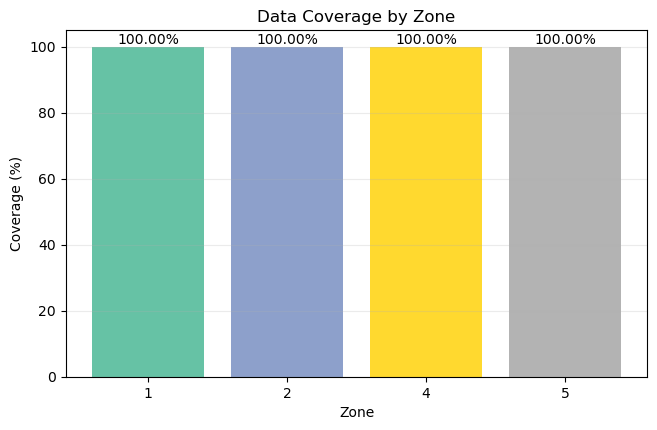

统计解释：选定 Zone 的时间覆盖率范围为 100.00% 到 100.00%。覆盖率越接近 100%，说明时间序列越完整，后续异常检测越不容易受到时间缺口影响。


,zone,expected_records,observed_records,missing_records,coverage_pct
0,1,90720,90720,0,100.0
1,2,90720,90720,0,100.0
2,4,90720,90720,0,100.0
3,5,90720,90720,0,100.0


In [32]:
def eda_01_data_coverage(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for (zone), group in df.groupby("zone"):
        expected = pd.date_range(ANALYSIS_START, ANALYSIS_END, freq="1min")
        observed = pd.DatetimeIndex(group["timestamp"].drop_duplicates().sort_values())
        rows.append({
            "zone": zone,
            "expected_records": len(expected),
            "observed_records": len(observed),
            "missing_records": len(expected.difference(observed)),
            "coverage_pct": len(observed) / len(expected) * 100,
        })
    coverage = pd.DataFrame(rows)
    save_table(coverage.round(4), "01_data_coverage.csv")

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.bar(coverage["zone"].astype(str), coverage["coverage_pct"], color=plt.cm.Set2(np.linspace(0, 1, len(coverage))))
    ax.set_title("Data Coverage by Zone")
    ax.set_xlabel("Zone")
    ax.set_ylabel("Coverage (%)")
    ax.set_ylim(0, 105)
    for idx, row in coverage.iterrows():
        ax.text(idx, row["coverage_pct"] + 1, f"{row['coverage_pct']:.2f}%", ha="center")
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("01_data_coverage.png")
    plt.show()

    min_cov = coverage["coverage_pct"].min()
    max_cov = coverage["coverage_pct"].max()
    print_cn(f"统计解释：选定 Zone 的时间覆盖率范围为 {min_cov:.2f}% 到 {max_cov:.2f}%。覆盖率越接近 100%，说明时间序列越完整，后续异常检测越不容易受到时间缺口影响。")
    return coverage

coverage_summary = eda_01_data_coverage(smoothed)
display(coverage_summary.round(4).head(20))

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\02_missing_rate_by_zone.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\02_missing_rate_heatmap.png


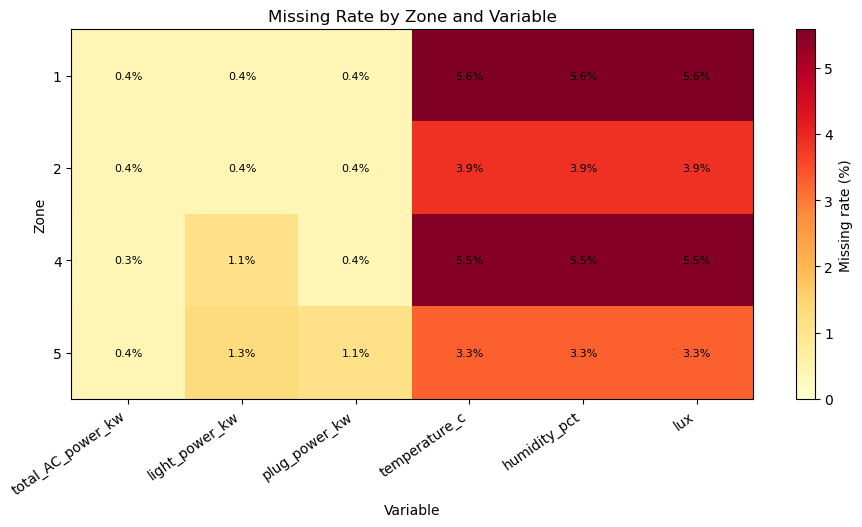

统计解释：原始数据最高缺失率出现在 Zone 1 的 temperature_c，缺失率为 5.58%。缺失值已在建模数据中完成填补，同时保留 *_was_missing 标记用于追踪这些位置。


,zone,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux
0,1,0.3505,0.3549,0.3549,5.5765,5.5765,5.5765
1,2,0.3505,0.3549,0.3527,3.8624,3.8624,3.8624
2,4,0.3450,1.1067,0.3616,5.5060,5.5060,5.5060
3,5,0.3505,1.2743,1.1067,3.2870,3.2870,3.2870


In [33]:
def eda_02_missing_rate(df: pd.DataFrame) -> pd.DataFrame:
    missing_flag_columns = [f"{column}_was_missing" for column in VALUE_COLUMNS]
    if all(column in df.columns for column in missing_flag_columns):
        missing = df.groupby("zone")[missing_flag_columns].apply(lambda x: x.mean() * 100).round(4).reset_index()
        missing = missing.rename(columns={f"{column}_was_missing": column for column in VALUE_COLUMNS})
    else:
        missing = df.groupby("zone")[VALUE_COLUMNS].apply(lambda x: x.isna().mean() * 100).round(4).reset_index()
    save_table(missing, "02_missing_rate_by_zone.csv")

    plot_data = missing.set_index("zone")[VALUE_COLUMNS]
    fig, ax = plt.subplots(figsize=(11, 4.8))
    im = ax.imshow(plot_data.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=max(1, np.nanmax(plot_data.values)))
    ax.set_title("Missing Rate by Zone and Variable")
    ax.set_xlabel("Variable")
    ax.set_ylabel("Zone")
    ax.set_xticks(range(len(plot_data.columns)))
    ax.set_xticklabels(plot_data.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(plot_data.index)))
    ax.set_yticklabels(plot_data.index)
    for i in range(plot_data.shape[0]):
        for j in range(plot_data.shape[1]):
            ax.text(j, i, f"{plot_data.iloc[i, j]:.1f}%", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, label="Missing rate (%)")
    save_current_figure("02_missing_rate_heatmap.png")
    plt.show()

    highest = missing.melt(id_vars="zone", var_name="variable", value_name="missing_pct").sort_values("missing_pct", ascending=False).iloc[0]
    print_cn(f"统计解释：原始数据最高缺失率出现在 Zone {int(highest['zone'])} 的 {highest['variable']}，缺失率为 {highest['missing_pct']:.2f}%。缺失值已在建模数据中完成填补，同时保留 *_was_missing 标记用于追踪这些位置。")
    return missing

missing_rate_summary = eda_02_missing_rate(smoothed)
display(missing_rate_summary.head(20))

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\03_duplicate_check.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\03_duplicate_check.png


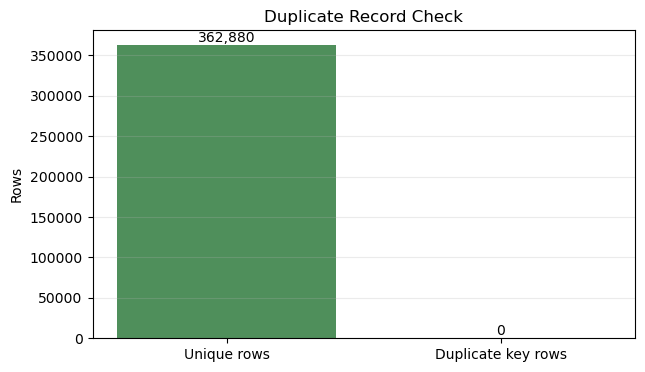

统计解释：以 timestamp + floor + zone 作为复合主键，重复记录数为 0，重复率为 0.0000%。重复率为 0 表示样本之间没有主键冲突。


,rows,key_columns,duplicate_key_rows,duplicate_rate_pct
0,362880,"timestamp, floor, zone",0,0.0


In [34]:
def eda_03_duplicate_check(df: pd.DataFrame) -> pd.DataFrame:
    duplicate_count = int(df.duplicated(KEY_COLUMNS).sum())
    summary = pd.DataFrame([{
        "rows": len(df),
        "key_columns": ", ".join(KEY_COLUMNS),
        "duplicate_key_rows": duplicate_count,
        "duplicate_rate_pct": duplicate_count / len(df) * 100 if len(df) else 0,
    }])
    save_table(summary.round(4), "03_duplicate_check.csv")

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(["Unique rows", "Duplicate key rows"], [len(df) - duplicate_count, duplicate_count], color=["#4f8f5b", "#b94d4d"])
    ax.set_title("Duplicate Record Check")
    ax.set_ylabel("Rows")
    ax.grid(axis="y", alpha=0.25)
    for i, v in enumerate([len(df) - duplicate_count, duplicate_count]):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom")
    save_current_figure("03_duplicate_check.png")
    plt.show()

    print_cn(f"统计解释：以 timestamp + floor + zone 作为复合主键，重复记录数为 {duplicate_count:,}，重复率为 {summary.loc[0, 'duplicate_rate_pct']:.4f}%。重复率为 0 表示样本之间没有主键冲突。")
    return summary

duplicate_check_summary = eda_03_duplicate_check(smoothed)
display(duplicate_check_summary.round(4).head(20))

In [35]:
smoothed = add_ac_operating_state(
    smoothed,
    variable="total_AC_power_kw",
    transition_buffer_min=ROLLING_WINDOW_RECORDS
)

smoothed.to_csv(FINAL_DATASET, index=False)
smoothed.to_csv(BASELINE_READY_DATASET, index=False)
smoothed.head(1000).to_csv(OUTPUT_DIR / "floor6_zone1245_cleaned_features_2018_jul01_sep01_preview.csv", index=False)
smoothed.head(1000).to_csv(OUTPUT_DIR / "floor6_zone1245_baseline_ready_2018_jul01_sep01_preview.csv", index=False)

print("Saved final dataset:", FINAL_DATASET)
print("Saved baseline-ready dataset:", BASELINE_READY_DATASET)
display(smoothed[["timestamp", "zone", "total_AC_power_kw", "ac_state", "transition_type", "ac_off_threshold_kw"]].head())

Saved final dataset: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\floor6_zone1245_cleaned_features_2018_jul01_sep01.csv.gz
Saved baseline-ready dataset: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz


,timestamp,zone,total_AC_power_kw,ac_state,transition_type,ac_off_threshold_kw
0,2018-07-01 00:00:00,1,0.0,OFF,None,0.5
1,2018-07-01 00:01:00,1,0.0,OFF,None,0.5
2,2018-07-01 00:02:00,1,0.0,OFF,None,0.5
3,2018-07-01 00:03:00,1,0.0,OFF,None,0.5
4,2018-07-01 00:04:00,1,0.0,OFF,None,0.5


## Data Processing / Model Preparation

In [36]:
def eda_00_raw_vs_rolling_mean(
    df: pd.DataFrame,
    zone: int = 2,
    variable: str = "total_AC_power_kw",
    days: int = 3
) -> pd.DataFrame:

    smooth_col = (
        f"{variable}_rolling_mean_"
        f"{ROLLING_WINDOW_RECORDS}min"
    )

    # --------------------------------------------------------
    # Select plotting period
    # --------------------------------------------------------
    start = df["timestamp"].min()
    end = start + pd.Timedelta(days=days)

    subset = (
        df[
            (df["zone"] == zone)
            & (df["timestamp"] >= start)
            & (df["timestamp"] < end)
        ]
        .copy()
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    if subset.empty:
        raise ValueError(
            f"No data found for Zone {zone} "
            f"between {start} and {end}."
        )

    # ========================================================
    # Plot: Raw vs Rolling Mean + Operating States
    # ========================================================

    fig, ax = plt.subplots(figsize=(14, 5.5))

    # --------------------------------------------------------
    # 1. Add operating-state background shading
    # --------------------------------------------------------

    state_colors = {
        "OFF": "#7FB3D5",          # blue
        "ON_stable": "#82E0AA",    # green
        "Transition": "#F1948A",   # red-orange
    }

    state_alpha = {
        "OFF": 0.30,
        "ON_stable": 0.30,
        "Transition": 0.38,
    }
    # Identify continuous state segments
    state_change = subset["ac_state"].ne(
        subset["ac_state"].shift()
    )

    segment_id = state_change.cumsum()

    for _, segment in subset.groupby(segment_id):

        state = segment["ac_state"].iloc[0]

        start_time = segment["timestamp"].iloc[0]
        end_time = segment["timestamp"].iloc[-1]

        # extend final timestamp by 1 minute for visual completeness
        end_time = end_time + pd.Timedelta(minutes=1)

        ax.axvspan(
            start_time,
            end_time,
            color=state_colors.get(state, "#ffffff"),
            alpha=state_alpha.get(state, 0.20),
            linewidth=0
        )


    # --------------------------------------------------------
    # 2. Raw 1-minute power
    # --------------------------------------------------------

    # Raw 1-minute power
    ax.plot(
        subset["timestamp"],
        subset[variable],
        label="Raw 1-min",
        linewidth=0.9,
        alpha=0.55,
        color="#4D4D4D"
    )

    # Rolling mean
    ax.plot(
        subset["timestamp"],
        subset[smooth_col],
        label=f"{ROLLING_WINDOW_RECORDS}-min rolling mean",
        linewidth=2.4,
        color="#003F8C"
    )


    # --------------------------------------------------------
    # 4. Labels and title
    # --------------------------------------------------------

    ax.set_title(
        f"Raw vs {ROLLING_WINDOW_RECORDS}-min Rolling Mean "
        f"with Operating States: Zone {zone} {variable}"
    )

    ax.set_xlabel("Timestamp")
    ax.set_ylabel(variable)

    ax.grid(True, alpha=0.25)


    # --------------------------------------------------------
    # 5. Custom legend
    # --------------------------------------------------------

    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D

    legend_items = [
        Line2D(
            [0], [0],
            color="#777777",
            linewidth=1.2,
            alpha=0.6,
            label="Raw 1-min"
        ),
        Line2D(
            [0], [0],
            color="#3264a8",
            linewidth=2.2,
            label=f"{ROLLING_WINDOW_RECORDS}-min rolling mean"
        ),
        Patch(
            facecolor=state_colors["OFF"],
            alpha=state_alpha["OFF"],
            label="OFF"
        ),
        Patch(
            facecolor=state_colors["ON_stable"],
            alpha=state_alpha["ON_stable"],
            label="ON stable"
        ),
        Patch(
            facecolor=state_colors["Transition"],
            alpha=state_alpha["Transition"],
            label="Transition"
        ),
    ]

    ax.legend(
        handles=legend_items,
        loc="upper left",
        ncol=2,
        frameon=True
    )


    # --------------------------------------------------------
    # 6. Formatting
    # --------------------------------------------------------

    fig.autofmt_xdate()

    plt.tight_layout()

    save_current_figure(
        f"00_raw_vs_{ROLLING_WINDOW_RECORDS}min_rolling_mean_states.png"
    )

    plt.show()

    # ========================================================
    # First difference
    #
    # Important:
    # Only calculate a valid difference when:
    #
    # 1. current and previous records are exactly 1 minute apart
    # 2. current and previous records have the same operating state
    #
    # This prevents startup / shutdown jumps from contaminating
    # ON_stable short-term variability.
    # ========================================================

    same_state_as_previous = (
        subset["ac_state"]
        == subset["ac_state"].shift(1)
    )

    continuous_one_minute = (
        subset["timestamp"].diff()
        == pd.Timedelta(minutes=1)
    )

    valid_diff = (
        same_state_as_previous
        & continuous_one_minute
    )

    subset["raw_diff"] = (
        subset[variable]
        .diff()
        .where(valid_diff)
    )

    subset["rolling_diff"] = (
        subset[smooth_col]
        .diff()
        .where(valid_diff)
    )

    # ========================================================
    # Statistics by operating state
    # ========================================================

    rows = []

    state_order = [
        "OFF",
        "ON_stable",
        "Transition"
    ]

    for state in state_order:

        g = subset[
            subset["ac_state"] == state
        ].copy()

        if g.empty:
            continue

        raw_std = g[variable].std()
        rolling_std = g[smooth_col].std()

        raw_diff_std = g["raw_diff"].std()
        rolling_diff_std = g["rolling_diff"].std()

        if (
            pd.notna(raw_diff_std)
            and raw_diff_std != 0
            and pd.notna(rolling_diff_std)
        ):
            short_term_reduction_pct = (
                1
                - rolling_diff_std / raw_diff_std
            ) * 100
        else:
            short_term_reduction_pct = np.nan

        rows.append({
            "zone": zone,
            "state": state,
            "n_records": len(g),

            "raw_mean": g[variable].mean(),
            "rolling_mean": g[smooth_col].mean(),

            "raw_std": raw_std,
            "rolling_std": rolling_std,

            "raw_diff_std": raw_diff_std,
            "rolling_diff_std": rolling_diff_std,

            "short_term_variation_reduction_pct":
                short_term_reduction_pct
        })

    stats = pd.DataFrame(rows)

    # --------------------------------------------------------
    # Save statistics
    # --------------------------------------------------------
    save_table(
        stats.round(4),
        "00_raw_vs_15min_rolling_mean_by_state.csv"
    )

    # ========================================================
    # Interpretation focused on ON_stable
    # ========================================================

    stable_row = stats[
        stats["state"] == "ON_stable"
    ]

    if not stable_row.empty:

        stable_row = stable_row.iloc[0]

        print_cn(
            f"统计解释：Zone {zone} 的 {variable} "
            f"按照功耗行为被划分为 OFF、ON_stable 和 Transition。"
            f"为评估 rolling mean 对分钟级短期波动的影响，"
            f"主要关注 ON_stable 状态，并排除 startup / shutdown "
            f"附近的 transition 时段。"
        )

        print_cn(
            f"在 ON_stable 状态下，原始 1 分钟功耗的 "
            f"first-difference 标准差为 "
            f"{stable_row['raw_diff_std']:.4f}，"
            f"经过 {ROLLING_WINDOW_RECORDS} 分钟 rolling mean 后为 "
            f"{stable_row['rolling_diff_std']:.4f}，"
            f"短期变化幅度下降约 "
            f"{stable_row['short_term_variation_reduction_pct']:.2f}%。"
        )

        print_cn(
            "该结果更直接反映 rolling mean 对稳定运行期间分钟级"
            "短时波动的平滑作用。Transition 状态中的较大变化主要"
            "反映真实的设备启动或关闭过程，因此不应简单解释为噪声。"
        )

    return stats

Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\00_raw_vs_15min_rolling_mean_states.png


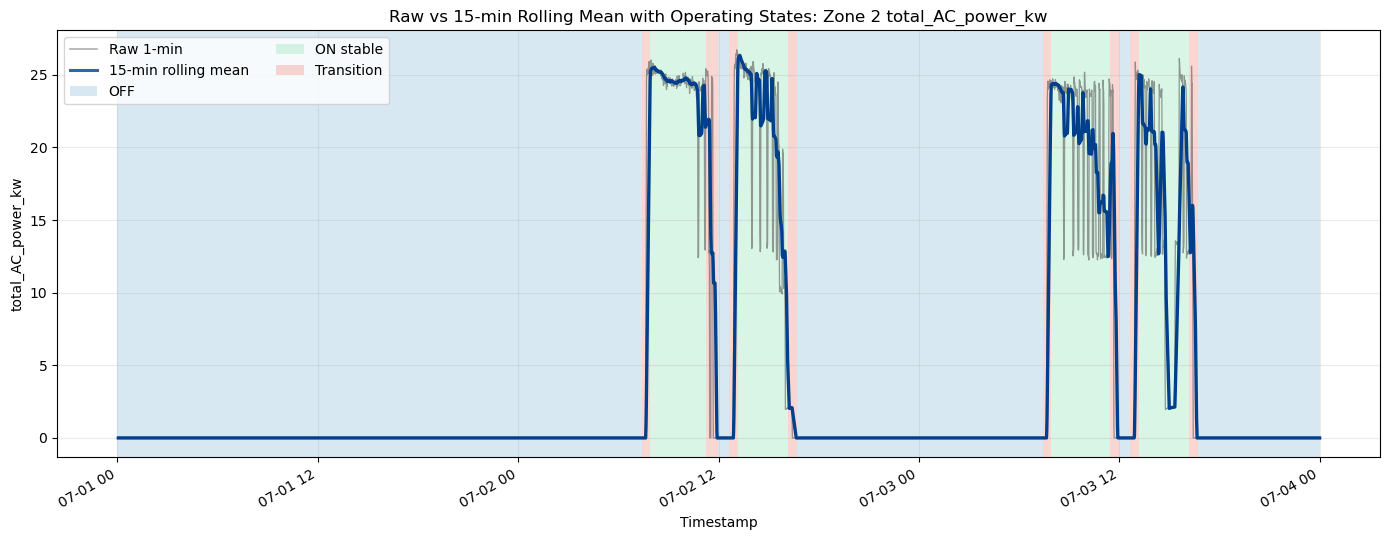

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\00_raw_vs_15min_rolling_mean_by_state.csv
统计解释：Zone 2 的 total_AC_power_kw 按照功耗行为被划分为 OFF、ON_stable 和 Transition。为评估 rolling mean 对分钟级短期波动的影响，主要关注 ON_stable 状态，并排除 startup / shutdown 附近的 transition 时段。
在 ON_stable 状态下，原始 1 分钟功耗的 first-difference 标准差为 2.3984，经过 15 分钟 rolling mean 后为 0.3962，短期变化幅度下降约 83.48%。
该结果更直接反映 rolling mean 对稳定运行期间分钟级短时波动的平滑作用。Transition 状态中的较大变化主要反映真实的设备启动或关闭过程，因此不应简单解释为噪声。


,zone,state,n_records,raw_mean,rolling_mean,raw_std,rolling_std,raw_diff_std,rolling_diff_std,short_term_variation_reduction_pct
0,2,OFF,3290,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN
1,2,ON_stable,769,20.3615,20.7797,6.7534,5.4586,2.3984,0.3962,83.4819
2,2,Transition,261,9.6520,8.4196,11.2514,8.1236,3.0423,0.9702,68.1104


In [37]:
rolling_comparison_stats = eda_00_raw_vs_rolling_mean(
    smoothed,
    zone=2,
    variable="total_AC_power_kw",
    days=3
)

display(rolling_comparison_stats.round(4))

## Temporal Patterns

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\04_daily_total_power_by_zone.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\04_daily_total_power_by_zone.png


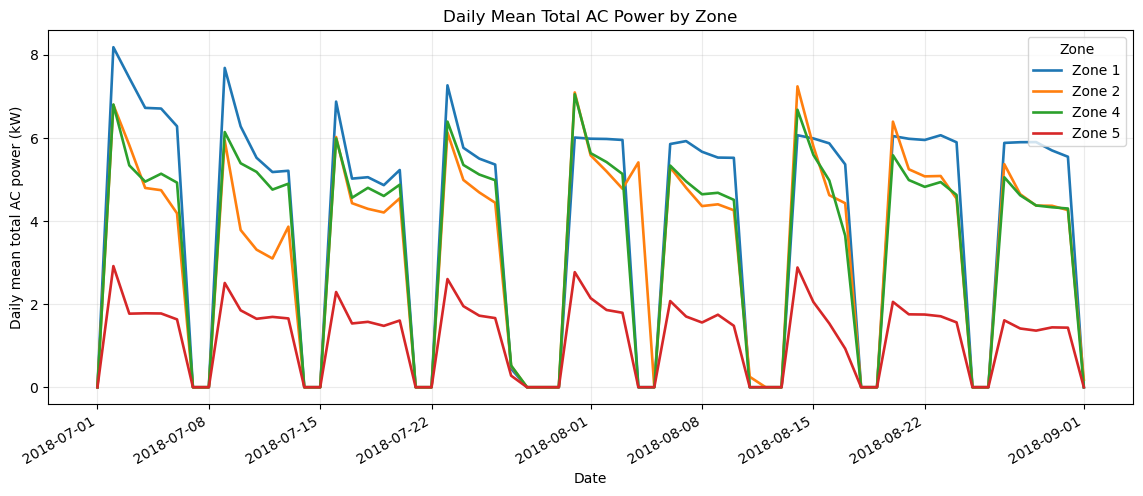

统计解释：日均总能耗最高的是 Zone 1，平均为 3.9869 kW。日均趋势可用于识别跨天持续偏高或偏低的异常模式。


,zone,date,daily_mean_total_AC_power_kw,daily_median_total_AC_power_kw,daily_std_total_AC_power_kw
0,1,2018-07-01,0.000000,0.0,0.000000
1,1,2018-07-02,8.184104,0.0,12.366095
2,1,2018-07-03,7.446424,0.0,11.573894
3,1,2018-07-04,6.723972,0.0,10.738194
4,1,2018-07-05,6.707944,0.0,10.713783
5,1,2018-07-06,6.281299,0.0,10.164435
6,1,2018-07-07,0.000000,0.0,0.000000
7,1,2018-07-08,0.000000,0.0,0.000000
8,1,2018-07-09,7.685993,0.0,11.969029
9,1,2018-07-10,6.278319,0.0,10.175896


In [38]:
def eda_04_daily_total_power_by_zone(df: pd.DataFrame) -> pd.DataFrame:
    daily = df.groupby(["zone", "date"]).agg(
        daily_mean_total_AC_power_kw=("total_AC_power_kw", "mean"),
        daily_median_total_AC_power_kw=("total_AC_power_kw", "median"),
        daily_std_total_AC_power_kw=("total_AC_power_kw", "std"),
    ).reset_index()
    save_table(daily.round(4), "04_daily_total_power_by_zone.csv")

    fig, ax = plt.subplots(figsize=(14, 5.5))
    for zone, group in daily.groupby("zone"):
        ax.plot(pd.to_datetime(group["date"]), group["daily_mean_total_AC_power_kw"], label=f"Zone {zone}", linewidth=1.9)
    ax.set_title("Daily Mean Total AC Power by Zone")
    ax.set_xlabel("Date")
    ax.set_ylabel("Daily mean total AC power (kW)")
    ax.legend(title="Zone")
    ax.grid(True, alpha=0.25)
    fig.autofmt_xdate()
    save_current_figure("04_daily_total_power_by_zone.png")
    plt.show()

    zone_means = daily.groupby("zone")["daily_mean_total_AC_power_kw"].mean().sort_values(ascending=False)
    print_cn(f"统计解释：日均总能耗最高的是 Zone {int(zone_means.index[0])}，平均为 {zone_means.iloc[0]:.4f} kW。日均趋势可用于识别跨天持续偏高或偏低的异常模式。")
    return daily

daily_total_power = eda_04_daily_total_power_by_zone(smoothed)
display(daily_total_power.head(20))

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\05_hourly_total_power_by_zone.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\05_hourly_total_power_by_zone.png


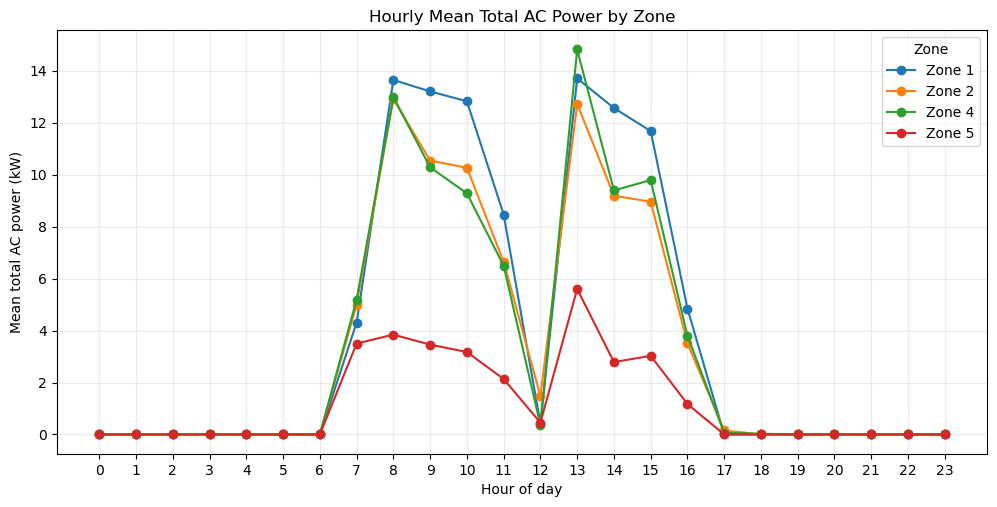

统计解释：小时均值最高点为 Zone 4 的 13:00，平均 total AC power 为 14.8217 kW。小时模式是建立正常用能 baseline 的核心依据。


,zone,hour,mean_total_AC_power_kw,median_total_AC_power_kw,std_total_AC_power_kw
0,1,0,0.000000,0.00,0.000000
1,1,1,0.000000,0.00,0.000000
2,1,2,0.000000,0.00,0.000000
3,1,3,0.000000,0.00,0.000000
4,1,4,0.000000,0.00,0.000000
5,1,5,0.000000,0.00,0.000000
6,1,6,0.000000,0.00,0.000000
7,1,7,4.308714,0.00,8.841416
8,1,8,13.648399,18.78,10.313928
9,1,9,13.207508,18.73,10.140528


In [39]:
def eda_05_hourly_total_power_by_zone(df: pd.DataFrame) -> pd.DataFrame:
    hourly = df.groupby(["zone", "hour"]).agg(
        mean_total_AC_power_kw=("total_AC_power_kw", "mean"),
        median_total_AC_power_kw=("total_AC_power_kw", "median"),
        std_total_AC_power_kw=("total_AC_power_kw", "std"),
    ).reset_index()
    save_table(hourly.round(4), "05_hourly_total_power_by_zone.csv")

    fig, ax = plt.subplots(figsize=(12, 5.5))
    for zone, group in hourly.groupby("zone"):
        ax.plot(group["hour"], group["mean_total_AC_power_kw"], marker="o", label=f"Zone {zone}")
    ax.set_title("Hourly Mean Total AC Power by Zone")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Mean total AC power (kW)")
    ax.set_xticks(range(24))
    ax.legend(title="Zone")
    ax.grid(True, alpha=0.25)
    save_current_figure("05_hourly_total_power_by_zone.png")
    plt.show()

    peak = hourly.loc[hourly["mean_total_AC_power_kw"].idxmax()]
    print_cn(f"统计解释：小时均值最高点为 Zone {int(peak['zone'])} 的 {int(peak['hour'])}:00，平均 total AC power 为 {peak['mean_total_AC_power_kw']:.4f} kW。小时模式是建立正常用能 baseline 的核心依据。")
    return hourly

hourly_total_power = eda_05_hourly_total_power_by_zone(smoothed)
display(hourly_total_power.head(20))

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\06_weekday_vs_weekend.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\06_weekday_vs_weekend.png


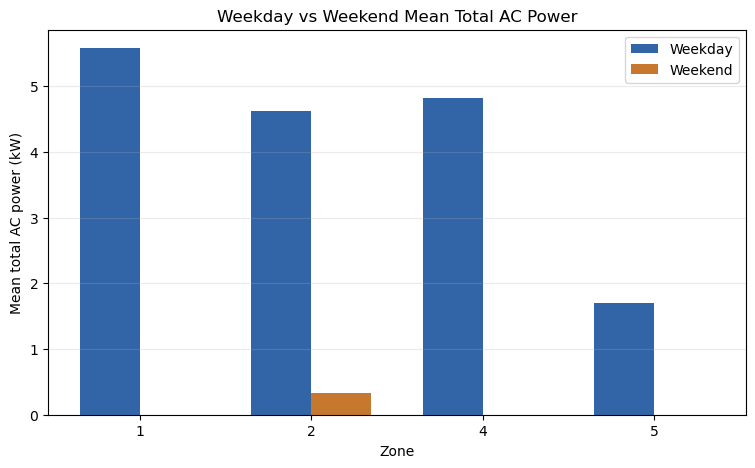

统计解释：工作日与周末差异最大的区域是 Zone 1，均值差为 5.5816 kW。该差异可用于识别非工作日异常用能。


,zone,day_type,mean_total_AC_power_kw,median_total_AC_power_kw,std_total_AC_power_kw,n
0,1,Weekday,5.5816,0.0,9.1574,64800
1,1,Weekend,0.0000,0.0,0.0000,25920
2,2,Weekday,4.6183,0.0,7.8517,64800
3,2,Weekend,0.3245,0.0,2.3087,25920
4,4,Weekday,4.8140,0.0,10.2929,64800
5,4,Weekend,0.0001,0.0,0.0014,25920
6,5,Weekday,1.7010,0.0,4.1397,64800
7,5,Weekend,0.0000,0.0,0.0026,25920


In [40]:
def eda_06_weekday_vs_weekend(df: pd.DataFrame) -> pd.DataFrame:
    summary = df.groupby(["zone", "day_type"]).agg(
        mean_total_AC_power_kw=("total_AC_power_kw", "mean"),
        median_total_AC_power_kw=("total_AC_power_kw", "median"),
        std_total_AC_power_kw=("total_AC_power_kw", "std"),
        n=("total_AC_power_kw", "count"),
    ).reset_index()
    save_table(summary.round(4), "06_weekday_vs_weekend.csv")

    zones = sorted(df["zone"].unique())
    positions = np.arange(len(zones))
    width = 0.35
    weekday = summary[summary["day_type"] == "Weekday"].set_index("zone").reindex(zones)
    weekend = summary[summary["day_type"] == "Weekend"].set_index("zone").reindex(zones)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(positions - width / 2, weekday["mean_total_AC_power_kw"], width, label="Weekday", color="#3264a8")
    ax.bar(positions + width / 2, weekend["mean_total_AC_power_kw"], width, label="Weekend", color="#c6782f")
    ax.set_title("Weekday vs Weekend Mean Total AC Power")
    ax.set_xlabel("Zone")
    ax.set_ylabel("Mean total AC power (kW)")
    ax.set_xticks(positions)
    ax.set_xticklabels(zones)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("06_weekday_vs_weekend.png")
    plt.show()

    merged = weekday[["mean_total_AC_power_kw"]].rename(columns={"mean_total_AC_power_kw": "weekday_mean"}).join(
        weekend[["mean_total_AC_power_kw"]].rename(columns={"mean_total_AC_power_kw": "weekend_mean"})
    )
    merged["weekday_minus_weekend"] = merged["weekday_mean"] - merged["weekend_mean"]
    strongest = merged["weekday_minus_weekend"].abs().idxmax()
    print_cn(f"统计解释：工作日与周末差异最大的区域是 Zone {int(strongest)}，均值差为 {merged.loc[strongest, 'weekday_minus_weekend']:.4f} kW。该差异可用于识别非工作日异常用能。")
    return summary

weekday_weekend_summary = eda_06_weekday_vs_weekend(smoothed)
display(weekday_weekend_summary.round(4).head(20))

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\07_zone_hour_heatmap.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\07_zone_hour_heatmap.png


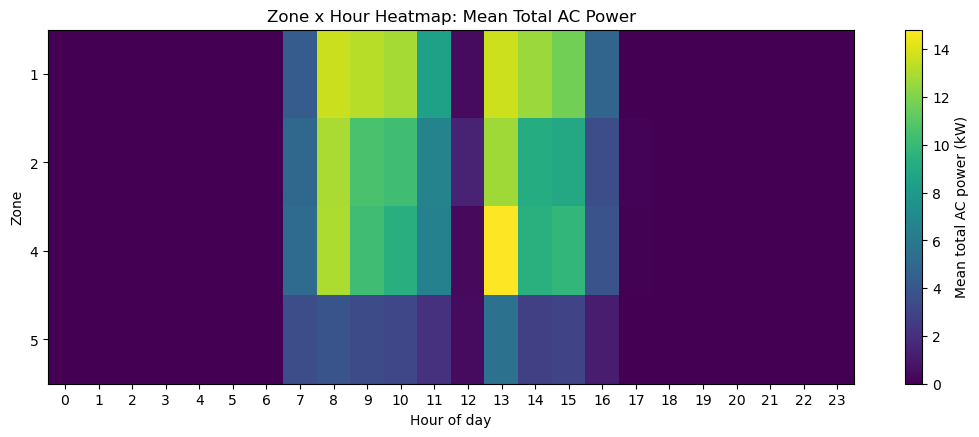

统计解释：热力图最高均值出现在 Zone 4 的 13:00。颜色块越亮表示该时段越接近高负载状态。


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
zone,,,,,,,,,,,,,,,,,,,,,,,,
1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,4.3087,13.6484,13.2075,12.8275,8.4676,0.4166,13.7106,12.5669,11.6815,4.8493,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000
2,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,5.0023,12.9120,10.5455,10.2678,6.6469,1.4791,12.7232,9.1927,8.9595,3.5097,0.1547,0.0022,0.0000,0.0000,0.0000,0.0,0.0000
4,0.0001,0.0001,0.0001,0.0001,0.0001,0.0001,0.006,5.1939,12.9928,10.2839,9.2849,6.4981,0.3664,14.8217,9.3944,9.7940,3.7956,0.0635,0.0283,0.0025,0.0001,0.0001,0.0,0.0001
5,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,3.4996,3.8437,3.4592,3.1741,2.1370,0.4530,5.6041,2.7870,3.0289,1.1735,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000


In [41]:
def eda_07_zone_hour_heatmap(df: pd.DataFrame) -> pd.DataFrame:
    heatmap = df.groupby(["zone", "hour"])["total_AC_power_kw"].mean().unstack("hour")
    save_table(heatmap.reset_index().round(4), "07_zone_hour_heatmap.csv")

    fig, ax = plt.subplots(figsize=(13, 4.6))
    im = ax.imshow(heatmap.values, aspect="auto", cmap="viridis")
    ax.set_title("Zone x Hour Heatmap: Mean Total AC Power")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Zone")
    ax.set_xticks(range(24))
    ax.set_xticklabels(range(24))
    ax.set_yticks(range(len(heatmap.index)))
    ax.set_yticklabels(heatmap.index)
    fig.colorbar(im, ax=ax, label="Mean total AC power (kW)")
    save_current_figure("07_zone_hour_heatmap.png")
    plt.show()

    max_zone, max_hour = np.unravel_index(np.nanargmax(heatmap.values), heatmap.shape)
    print_cn(f"统计解释：热力图最高均值出现在 Zone {int(heatmap.index[max_zone])} 的 {int(heatmap.columns[max_hour])}:00。颜色块越亮表示该时段越接近高负载状态。")
    return heatmap

zone_hour_heatmap = eda_07_zone_hour_heatmap(smoothed)
display(zone_hour_heatmap.round(4).head(20))

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\08_two_month_overall_trend.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\08_two_month_overall_trend.png


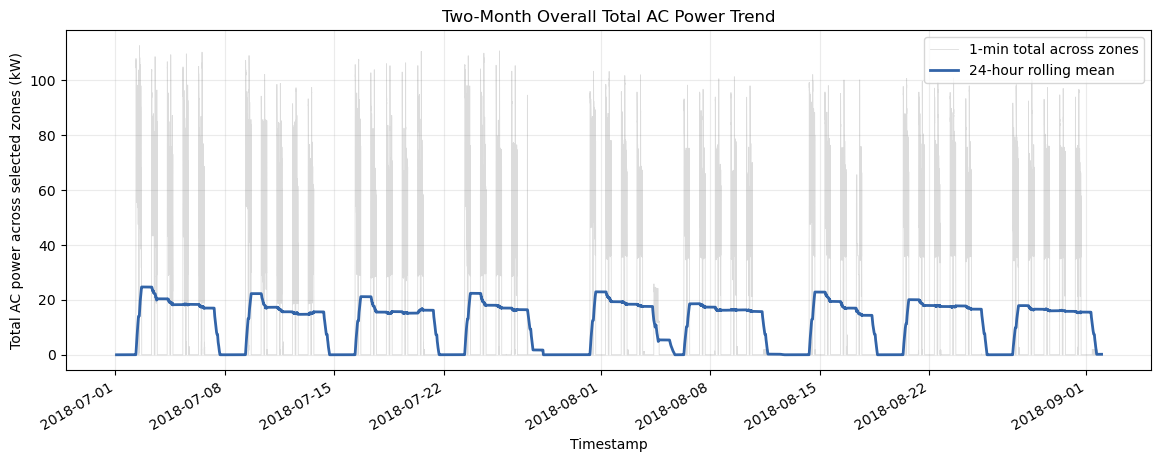

统计解释：首日平均总负载为 0.0000 kW，末日平均总负载为 0.1790 kW。两个月总体趋势可帮助判断是否存在长期漂移或季节性变化。


,timestamp,building_total_AC_power_kw,building_mean_total_AC_power_kw,building_total_AC_power_rolling_24h
0,2018-07-01 00:00:00,0.0,0.0,NaN
1,2018-07-01 00:01:00,0.0,0.0,NaN
2,2018-07-01 00:02:00,0.0,0.0,NaN
3,2018-07-01 00:03:00,0.0,0.0,NaN
4,2018-07-01 00:04:00,0.0,0.0,NaN
5,2018-07-01 00:05:00,0.0,0.0,NaN
6,2018-07-01 00:06:00,0.0,0.0,NaN
7,2018-07-01 00:07:00,0.0,0.0,NaN
8,2018-07-01 00:08:00,0.0,0.0,NaN
9,2018-07-01 00:09:00,0.0,0.0,NaN


In [42]:
def eda_08_two_month_overall_trend(df: pd.DataFrame) -> pd.DataFrame:
    overall = df.groupby("timestamp").agg(
        building_total_AC_power_kw=("total_AC_power_kw", "sum"),
        building_mean_total_AC_power_kw=("total_AC_power_kw", "mean"),
    ).reset_index()
    overall["building_total_AC_power_rolling_24h"] = overall["building_total_AC_power_kw"].rolling(window=1440, min_periods=120).mean()
    save_table(overall.round(4), "08_two_month_overall_trend.csv")

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(overall["timestamp"], overall["building_total_AC_power_kw"], color="#777777", alpha=0.25, linewidth=0.6, label="1-min total across zones")
    ax.plot(overall["timestamp"], overall["building_total_AC_power_rolling_24h"], color="#3264a8", linewidth=2.0, label="24-hour rolling mean")
    ax.set_title("Two-Month Overall Total AC Power Trend")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Total AC power across selected zones (kW)")
    ax.legend()
    ax.grid(True, alpha=0.25)
    fig.autofmt_xdate()
    save_current_figure("08_two_month_overall_trend.png")
    plt.show()

    start_mean = overall.head(1440)["building_total_AC_power_kw"].mean()
    end_mean = overall.tail(1440)["building_total_AC_power_kw"].mean()
    print_cn(f"统计解释：首日平均总负载为 {start_mean:.4f} kW，末日平均总负载为 {end_mean:.4f} kW。两个月总体趋势可帮助判断是否存在长期漂移或季节性变化。")
    return overall

two_month_trend = eda_08_two_month_overall_trend(smoothed)
display(two_month_trend.head(20))

## Energy Distribution

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\09_total_power_distribution_stats.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\09_total_power_distribution.png


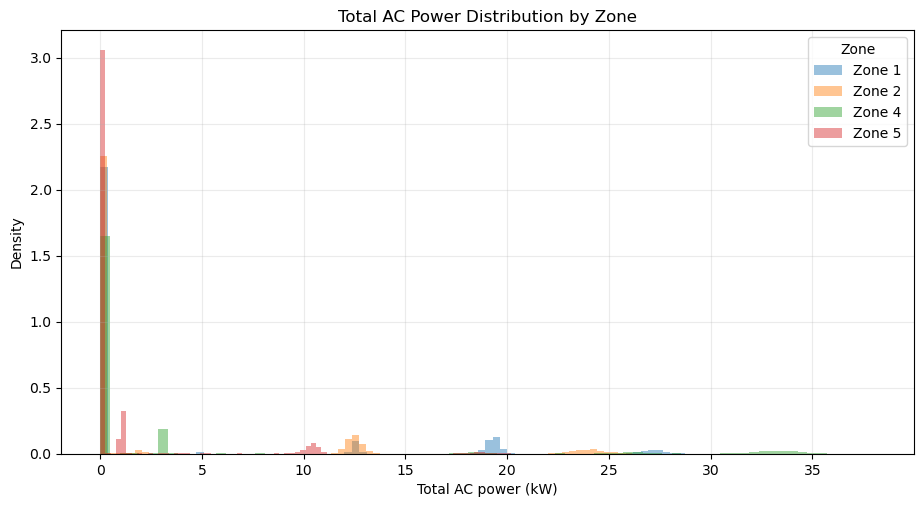

统计解释：偏度绝对值最大的是 Zone 5，skew=3.3703。正偏明显时，说明少量高功耗点拉长右尾，这类点常是异常检测关注对象。


,zone,count,mean,median,std,min,max,skew,cv,iqr_outlier_rate_pct
0,1,90720,3.9869,0.0,8.1398,0.0,29.10,1.7411,2.0417,0.0
1,2,90720,3.3915,0.0,7.0228,0.0,27.52,1.9360,2.0707,0.0
2,4,90720,3.4386,0.0,8.9668,0.0,38.08,2.6541,2.6077,0.0
3,5,90720,1.2150,0.0,3.5820,0.0,20.70,3.3703,2.9482,0.0


In [43]:
def eda_09_total_power_distribution(df: pd.DataFrame) -> pd.DataFrame:
    stats = df.groupby("zone")["total_AC_power_kw"].agg(["count", "mean", "median", "std", "min", "max", "skew"]).reset_index()
    stats["cv"] = df.groupby("zone")["total_AC_power_kw"].apply(coefficient_of_variation).values
    stats["iqr_outlier_rate_pct"] = df.groupby("zone")["total_AC_power_kw"].apply(iqr_outlier_rate).values
    save_table(stats.round(4), "09_total_power_distribution_stats.csv")

    fig, ax = plt.subplots(figsize=(11, 5.5))
    for zone, group in df.groupby("zone"):
        ax.hist(group["total_AC_power_kw"].dropna(), bins=80, alpha=0.45, density=True, label=f"Zone {zone}")
    ax.set_title("Total AC Power Distribution by Zone")
    ax.set_xlabel("Total AC power (kW)")
    ax.set_ylabel("Density")
    ax.legend(title="Zone")
    ax.grid(True, alpha=0.25)
    save_current_figure("09_total_power_distribution.png")
    plt.show()

    skewed_zone = stats.iloc[stats["skew"].abs().idxmax()]
    print_cn(f"统计解释：偏度绝对值最大的是 Zone {int(skewed_zone['zone'])}，skew={skewed_zone['skew']:.4f}。正偏明显时，说明少量高功耗点拉长右尾，这类点常是异常检测关注对象。")
    return stats

total_power_distribution_stats = eda_09_total_power_distribution(smoothed)
display(total_power_distribution_stats.round(4).head(20))

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\11_ac_light_plug_composition.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\11_ac_light_plug_composition.png


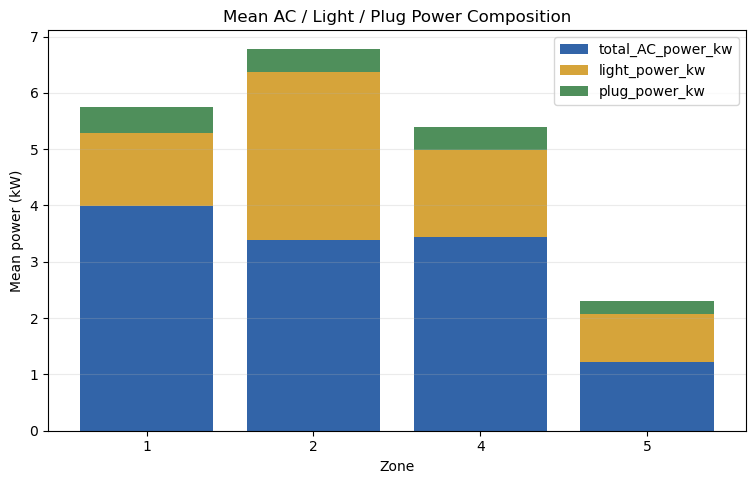

统计解释：Zone 1 的平均 AC 能耗最高。Floor 6 的 Zone 1、2、4、5 均有 AC meter，其中多 AC meter 的区域已先聚合为单一 total_AC_power_kw，因此不同 Zone 可以在同一特征结构下比较。


,zone,component,mean_power_kw
0,1,total_AC_power_kw,3.9869
1,2,total_AC_power_kw,3.3915
2,4,total_AC_power_kw,3.4386
3,5,total_AC_power_kw,1.2150
4,1,light_power_kw,1.3022
5,2,light_power_kw,2.9770
6,4,light_power_kw,1.5458
7,5,light_power_kw,0.8646
8,1,plug_power_kw,0.4580
9,2,plug_power_kw,0.4031


In [44]:
def eda_11_ac_light_plug_composition(df: pd.DataFrame) -> pd.DataFrame:
    composition = df.groupby("zone")[COMPONENT_POWER_COLUMNS].mean().reset_index()
    composition_long = composition.melt(id_vars="zone", var_name="component", value_name="mean_power_kw")
    save_table(composition_long.round(4), "11_ac_light_plug_composition.csv")

    plot_data = composition.set_index("zone")
    fig, ax = plt.subplots(figsize=(9, 5.2))
    bottom = np.zeros(len(plot_data))
    colors = {"total_AC_power_kw": "#3264a8", "light_power_kw": "#d6a43a", "plug_power_kw": "#4f8f5b"}
    for column in COMPONENT_POWER_COLUMNS:
        values = plot_data[column].fillna(0).values
        ax.bar(plot_data.index.astype(str), values, bottom=bottom, label=column, color=colors[column])
        bottom += values
    ax.set_title("Mean AC / Light / Plug Power Composition")
    ax.set_xlabel("Zone")
    ax.set_ylabel("Mean power (kW)")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("11_ac_light_plug_composition.png")
    plt.show()

    ac_mean = composition.set_index("zone")["total_AC_power_kw"]
    top_ac_zone = ac_mean.idxmax(skipna=True)
    print_cn(f"统计解释：Zone {int(top_ac_zone)} 的平均 AC 能耗最高。Floor 6 的 Zone 1、2、4、5 均有 AC meter，其中多 AC meter 的区域已先聚合为单一 total_AC_power_kw，因此不同 Zone 可以在同一特征结构下比较。")
    return composition_long

composition_summary = eda_11_ac_light_plug_composition(smoothed)
display(composition_summary.round(4).head(20))

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\12_top_n_high_total_AC_power_records.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\12_top_n_high_total_AC_power_records.png


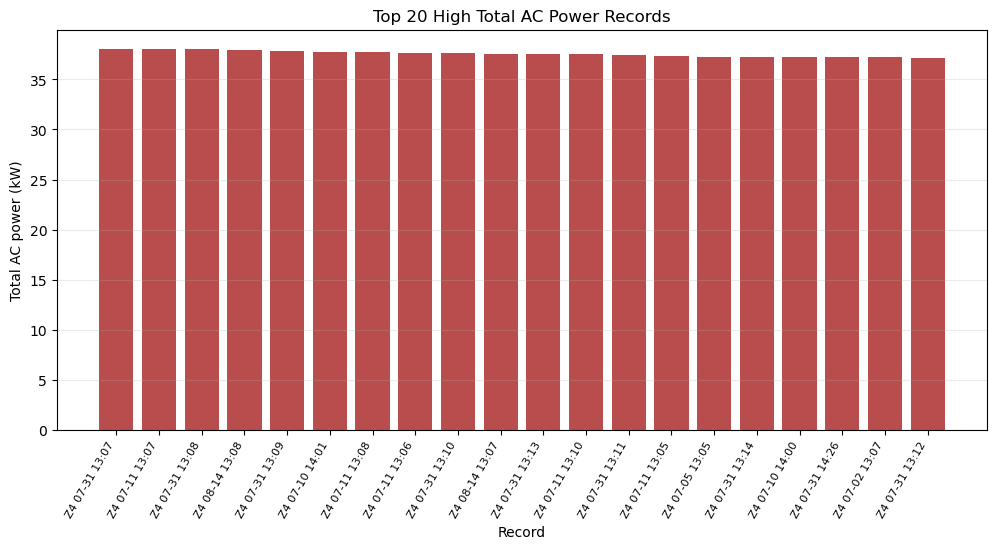

统计解释：Top 20 高功耗记录中，出现最多的是 Zone 4，共 20 条。这些记录可作为后续异常检测结果解释时的候选高 AC 负载样本。


,timestamp,floor,zone,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,day_type,hour
0,2018-07-31 13:07:00,6,4,38.08,4.17,1.27,26.620000,59.440000,28.000000,Weekday,13
1,2018-07-11 13:07:00,6,4,38.06,4.01,1.66,24.680000,65.320000,43.000000,Weekday,13
2,2018-07-31 13:08:00,6,4,37.99,4.31,1.24,26.420000,59.400000,29.000000,Weekday,13
3,2018-08-14 13:08:00,6,4,37.92,4.32,2.19,26.170000,57.860000,31.000000,Weekday,13
4,2018-07-31 13:09:00,6,4,37.86,4.33,2.27,26.230000,59.370000,29.000000,Weekday,13
5,2018-07-10 14:01:00,6,4,37.77,4.56,1.23,22.430000,70.750000,42.000000,Weekday,14
6,2018-07-11 13:08:00,6,4,37.70,4.02,1.65,24.530000,65.160000,43.000000,Weekday,13
7,2018-07-11 13:06:00,6,4,37.63,4.01,1.61,25.066000,65.514000,42.600000,Weekday,13
8,2018-07-31 13:10:00,6,4,37.60,4.33,1.60,26.500000,59.350000,29.000000,Weekday,13
9,2018-08-14 13:07:00,6,4,37.57,4.34,1.53,26.360000,57.880000,31.000000,Weekday,13


In [45]:
def eda_12_top_n_high_total_ac_power_records(df: pd.DataFrame, n: int = 20) -> pd.DataFrame:
    columns = ["timestamp", "floor", "zone", "total_AC_power_kw", "light_power_kw", "plug_power_kw", "temperature_c", "humidity_pct", "lux", "day_type", "hour"]
    top_records = df.sort_values("total_AC_power_kw", ascending=False)[columns].head(n).reset_index(drop=True)
    save_table(top_records.round(4), "12_top_n_high_total_AC_power_records.csv")

    fig, ax = plt.subplots(figsize=(12, 5.2))
    labels = top_records.apply(lambda row: f"Z{int(row['zone'])} {row['timestamp'].strftime('%m-%d %H:%M')}", axis=1)
    ax.bar(range(len(top_records)), top_records["total_AC_power_kw"], color="#b94d4d")
    ax.set_title(f"Top {n} High Total AC Power Records")
    ax.set_xlabel("Record")
    ax.set_ylabel("Total AC power (kW)")
    ax.set_xticks(range(len(top_records)))
    ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("12_top_n_high_total_AC_power_records.png")
    plt.show()

    zone_counts = top_records["zone"].value_counts().sort_index()
    dominant_zone = zone_counts.idxmax()
    print_cn(f"统计解释：Top {n} 高功耗记录中，出现最多的是 Zone {int(dominant_zone)}，共 {int(zone_counts.loc[dominant_zone])} 条。这些记录可作为后续异常检测结果解释时的候选高 AC 负载样本。")
    return top_records

top_high_total_ac_power_records = eda_12_top_n_high_total_ac_power_records(smoothed, n=20)
display(top_high_total_ac_power_records.head(20))

## Variable Relationships

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\13_correlation_heatmap.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\13_correlation_heatmap.png


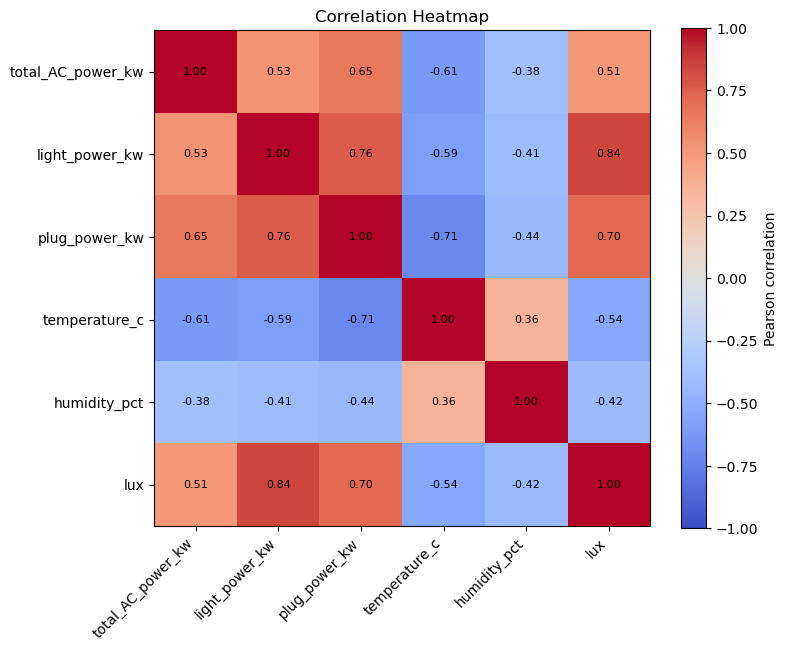

统计解释：绝对相关系数最高的变量对是 lux 与 light_power_kw，|r|=0.8429。高相关变量可能提供相似信息，建模时可检查是否存在特征冗余。


,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux
total_AC_power_kw,1.0000,0.5271,0.6455,-0.6107,-0.3814,0.5065
light_power_kw,0.5271,1.0000,0.7594,-0.5868,-0.4083,0.8429
plug_power_kw,0.6455,0.7594,1.0000,-0.7137,-0.4360,0.7049
temperature_c,-0.6107,-0.5868,-0.7137,1.0000,0.3557,-0.5364
humidity_pct,-0.3814,-0.4083,-0.4360,0.3557,1.0000,-0.4183
lux,0.5065,0.8429,0.7049,-0.5364,-0.4183,1.0000


In [46]:
def eda_13_correlation_heatmap(df: pd.DataFrame) -> pd.DataFrame:
    corr = df[VALUE_COLUMNS].corr(numeric_only=True)
    save_table(corr.reset_index().rename(columns={"index": "variable"}).round(4), "13_correlation_heatmap.csv")

    fig, ax = plt.subplots(figsize=(8, 6.5))
    im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_title("Correlation Heatmap")
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.index)))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticklabels(corr.index)
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, label="Pearson correlation")
    save_current_figure("13_correlation_heatmap.png")
    plt.show()

    corr_pairs = corr.where(~np.eye(corr.shape[0], dtype=bool)).stack().abs().sort_values(ascending=False)
    top_pair = corr_pairs.index[0]
    print_cn(f"统计解释：绝对相关系数最高的变量对是 {top_pair[0]} 与 {top_pair[1]}，|r|={corr_pairs.iloc[0]:.4f}。高相关变量可能提供相似信息，建模时可检查是否存在特征冗余。")
    return corr

correlation_matrix = eda_13_correlation_heatmap(smoothed)
display(correlation_matrix.round(4).head(20))

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\14_temperature_vs_total_ac_power_stats.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\14_temperature_vs_total_ac_power.png


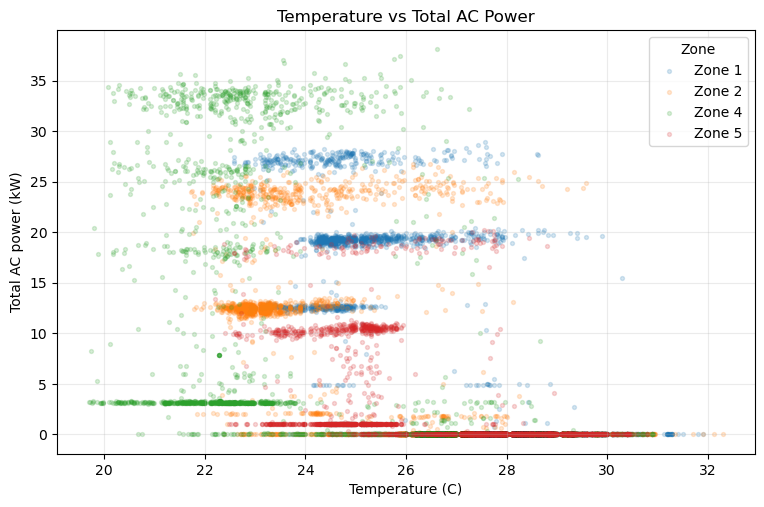

统计解释：Temperature 与 Total AC Power 相关性最强的是 Zone 1，Pearson r=-0.7001，完整样本数为 90,720。相关系数接近 0 表示线性关系较弱。


,zone,pearson_r,n_complete
0,1,-0.7001,90720
1,2,-0.6880,90720
2,4,-0.5956,90720
3,5,-0.4893,90720


In [47]:
def eda_14_temperature_vs_total_ac_power(df: pd.DataFrame, sample_size: int = 25000) -> pd.DataFrame:
    subset = df[["zone", "temperature_c", "total_AC_power_kw"]].dropna()
    if len(subset) > sample_size:
        subset = subset.sample(sample_size, random_state=42)

    stats = df.groupby("zone").apply(lambda g: g[["temperature_c", "total_AC_power_kw"]].corr().iloc[0, 1]).reset_index(name="pearson_r")
    stats["n_complete"] = df.groupby("zone").apply(lambda g: g[["temperature_c", "total_AC_power_kw"]].dropna().shape[0]).values
    save_table(stats.round(4), "14_temperature_vs_total_ac_power_stats.csv")

    fig, ax = plt.subplots(figsize=(9, 5.5))
    for zone, group in subset.groupby("zone"):
        ax.scatter(group["temperature_c"], group["total_AC_power_kw"], s=8, alpha=0.18, label=f"Zone {zone}")
    ax.set_title("Temperature vs Total AC Power")
    ax.set_xlabel("Temperature (C)")
    ax.set_ylabel("Total AC power (kW)")
    ax.legend(title="Zone")
    ax.grid(True, alpha=0.25)
    save_current_figure("14_temperature_vs_total_ac_power.png")
    plt.show()

    strongest = stats.loc[stats["pearson_r"].abs().idxmax()]
    print_cn(f"统计解释：Temperature 与 Total AC Power 相关性最强的是 Zone {int(strongest['zone'])}，Pearson r={strongest['pearson_r']:.4f}，完整样本数为 {int(strongest['n_complete']):,}。相关系数接近 0 表示线性关系较弱。")
    return stats

temperature_total_ac_power_stats = eda_14_temperature_vs_total_ac_power(smoothed)
display(temperature_total_ac_power_stats.round(4).head(20))

Saved table: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables\15_lux_vs_light_power_stats.csv
Saved figure: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures\15_lux_vs_light_power.png


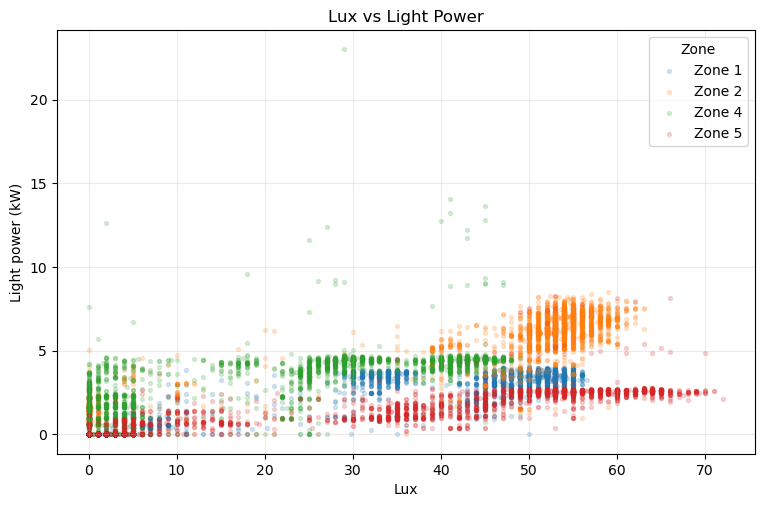

统计解释：Lux 与 Light Power 相关性最强的是 Zone 2，Pearson r=0.9659，完整样本数为 90,720。该图可检验照度变化是否与照明能耗同步。


,zone,pearson_r,n_complete
0,1,0.9580,90720
1,2,0.9659,90720
2,4,0.8587,90720
3,5,0.9430,90720


In [48]:
def eda_15_lux_vs_light_power(df: pd.DataFrame, sample_size: int = 25000) -> pd.DataFrame:
    subset = df[["zone", "lux", "light_power_kw"]].dropna()
    if len(subset) > sample_size:
        subset = subset.sample(sample_size, random_state=42)

    stats = df.groupby("zone").apply(lambda g: g[["lux", "light_power_kw"]].corr().iloc[0, 1]).reset_index(name="pearson_r")
    stats["n_complete"] = df.groupby("zone").apply(lambda g: g[["lux", "light_power_kw"]].dropna().shape[0]).values
    save_table(stats.round(4), "15_lux_vs_light_power_stats.csv")

    fig, ax = plt.subplots(figsize=(9, 5.5))
    for zone, group in subset.groupby("zone"):
        ax.scatter(group["lux"], group["light_power_kw"], s=8, alpha=0.18, label=f"Zone {zone}")
    ax.set_title("Lux vs Light Power")
    ax.set_xlabel("Lux")
    ax.set_ylabel("Light power (kW)")
    ax.legend(title="Zone")
    ax.grid(True, alpha=0.25)
    save_current_figure("15_lux_vs_light_power.png")
    plt.show()

    strongest = stats.loc[stats["pearson_r"].abs().idxmax()]
    print_cn(f"统计解释：Lux 与 Light Power 相关性最强的是 Zone {int(strongest['zone'])}，Pearson r={strongest['pearson_r']:.4f}，完整样本数为 {int(strongest['n_complete']):,}。该图可检验照度变化是否与照明能耗同步。")
    return stats

lux_light_power_stats = eda_15_lux_vs_light_power(smoothed)
display(lux_light_power_stats.round(4).head(20))

## 9. Final Validation

In [49]:
def final_validation(df: pd.DataFrame) -> pd.DataFrame:
    summary = pd.DataFrame([{
        "final_dataset": FINAL_DATASET.name,
        "rows": len(df),
        "columns": len(df.columns),
        "floor": FLOOR,
        "zones": ",".join(map(str, sorted(df["zone"].unique()))),
        "min_timestamp": df["timestamp"].min(),
        "max_timestamp": df["timestamp"].max(),
        "key_columns": ", ".join(KEY_COLUMNS),
        "duplicate_key_rows": int(df.duplicated(KEY_COLUMNS).sum()),
        "rolling_window_records": ROLLING_WINDOW_RECORDS,
        "rolling_min_periods": ROLLING_MIN_PERIODS,
        "figure_count": len(list(FIGURE_DIR.glob("*.png"))),
        "eda_table_count": len(list(TABLE_DIR.glob("*.csv"))),
    }])
    summary.to_csv(OUTPUT_DIR / "13_final_validation_summary.csv", index=False)
    return summary

validation_summary = final_validation(smoothed)
display(validation_summary.head(20))
print("Main output:", FINAL_DATASET)
print("Preview:", OUTPUT_DIR / "floor6_zone1245_cleaned_smoothed_2018_jul01_sep01_preview.csv")
print("Figures:", FIGURE_DIR)
print("EDA tables:", TABLE_DIR)

,final_dataset,rows,columns,floor,zones,min_timestamp,max_timestamp,key_columns,duplicate_key_rows,rolling_window_records,rolling_min_periods,figure_count,eda_table_count
0,floor6_zone1245_cleaned_features_2018_jul01_se...,362880,38,6,"1,2,4,5",2018-07-01,2018-09-01 23:59:00,"timestamp, floor, zone",0,15,5,17,17


Main output: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\floor6_zone1245_cleaned_features_2018_jul01_sep01.csv.gz
Preview: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\floor6_zone1245_cleaned_smoothed_2018_jul01_sep01_preview.csv
Figures: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\figures
EDA tables: d:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\eda_tables


## 10. Notes for Anomaly Detection

最终建模表采用复合主键：

```text
timestamp + floor + zone
```

建议后续 anomaly detection 使用 rolling mean 后的稳定特征作为主输入，并保留原始变量用于解释异常点。Floor 6 的 Zone 1、2、4、5 均有 AC meter；其中 Zone 4 的 `total_AC_power_kw` 来自多个 AC meter 的区域级求和。如果训练 AC-specific model，可以直接使用这些 Zone 的 `total_AC_power_kw`。